# Smart MCQ Solver — Semantic Similarity & Transformer-Based Answer Ranking
**DL / GenAI Project · Student ID: 24f1002692**

An end-to-end pipeline that ranks the top-3 most probable answers for multiple-choice 
questions, evaluated with MAP@3. Progresses from classical NLP baselines (TF-IDF, Word2Vec) 
to pretrained transformer approaches (BERT/RoBERTa embeddings, Sentence-Transformers, 
zero-shot NLI classification), then to Retrieval-Augmented Generation (Wikipedia FAISS 
index + Flan-T5 reader), followed by multiple-choice classification with LoRA fine-tuning 
of BERT, and sequence classification + ensembling of fine-tuned DeBERTa and RoBERTa models. 
Finally, builds a from-scratch Bidirectional GRU with attention pooling — trained without 
any pretrained weights, but fed **RAG-retrieved Wikipedia context** alongside the prompt 
and options to reduce overfitting and improve generalization on the small training set. 
Concludes with a train-vs-validation MAP@3 overfit check for the RAG-augmented scratch 
model, followed by loading the best checkpoint and generating the final test-set submission.

## Import Basic Libraries

In [1]:
import os, re, io, sys, string, warnings, logging, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
from tqdm import tqdm

# HuggingFace Hub download bars + auth warning
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
os.environ["HF_HUB_DISABLE_TELEMETRY"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

from huggingface_hub.utils import disable_progress_bars
disable_progress_bars()

# datasets library (.map(), load_dataset) progress bars
from datasets.utils.logging import disable_progress_bar as ds_disable_progress_bar
ds_disable_progress_bar()

# transformers logging (loading model/config messages)
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

# general warnings
warnings.filterwarnings("ignore")
logging.getLogger("transformers").setLevel(logging.ERROR)
logging.getLogger("datasets").setLevel(logging.ERROR)

In [2]:
!pip install wandb -q
import wandb
from kaggle_secrets import UserSecretsClient

wandb_key = UserSecretsClient().get_secret("WANDB_API_KEY")
login_success = wandb.login(key=wandb_key)
print("wandb.login() returned:", login_success)

if login_success:
    print("Logged into W&B successfully")
else:
    print("W&B login failed")

# check the API to see current user
api = wandb.Api()
print("Logged in as:", api.viewer.username)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: 24f1002692 (24f1002692-dl-genai-project) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb.login() returned: True
Logged into W&B successfully
Logged in as: 24f1002692


In [3]:
warnings.filterwarnings('ignore')

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv
/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv
/kaggle/input/datasets/jjinho/wikipedia-2023-07-faiss-index/wikipedia_202307.index
/kaggle/input/datasets/jjinho/wikipedia-20230701/x.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/h.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/w.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/g.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/a.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/y.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/l.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/n.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/i.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/number.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/j.parquet
/kaggle/input/datasets/jjinho/wikipedia-20230701/m.parquet
/

## Load Train and test datasets

In [4]:
sample_submission = pd.read_csv(
    "/kaggle/input/competitions/smart-mcq-solver-challenge/sample_submission.csv"
)
train_dataset = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv")
test_dataset = pd.read_csv("/kaggle/input/competitions/smart-mcq-solver-challenge/test.csv")

if 'id' in train_dataset.columns:
    train_dataset = train_dataset.drop(columns=['id'])

print('Train shape:', train_dataset.shape)   # (2000, 7)
print('Test shape :', test_dataset.shape)    # (500, 6)
print('Columns    :', train_dataset.columns.tolist())
print('Answer dist:', train_dataset['answer'].value_counts().to_dict())

Train shape: (2000, 7)
Test shape : (500, 7)
Columns    : ['prompt', 'A', 'B', 'C', 'D', 'E', 'answer']
Answer dist: {'B': 490, 'C': 459, 'A': 369, 'D': 358, 'E': 324}


## Exploratory Data Analysis

  DATASET OVERVIEW
  Rows                  : 2,000
  Nulls                 : 0
  Duplicate prompts     : 242
  Unique option texts   : 1,584 / 10,000

  Answer distribution:
    A  369  (18.4%)
    B  490  (24.5%)
    C  459  (22.9%)
    D  358  (17.9%)
    E  324  (16.2%)

  Correct option avg len    : 181.9 chars
  Wrong  option avg len     : 160.7 chars
  longest option is correct : 40.6% of the time
  Avg total tokens/question : 236  (max 651)


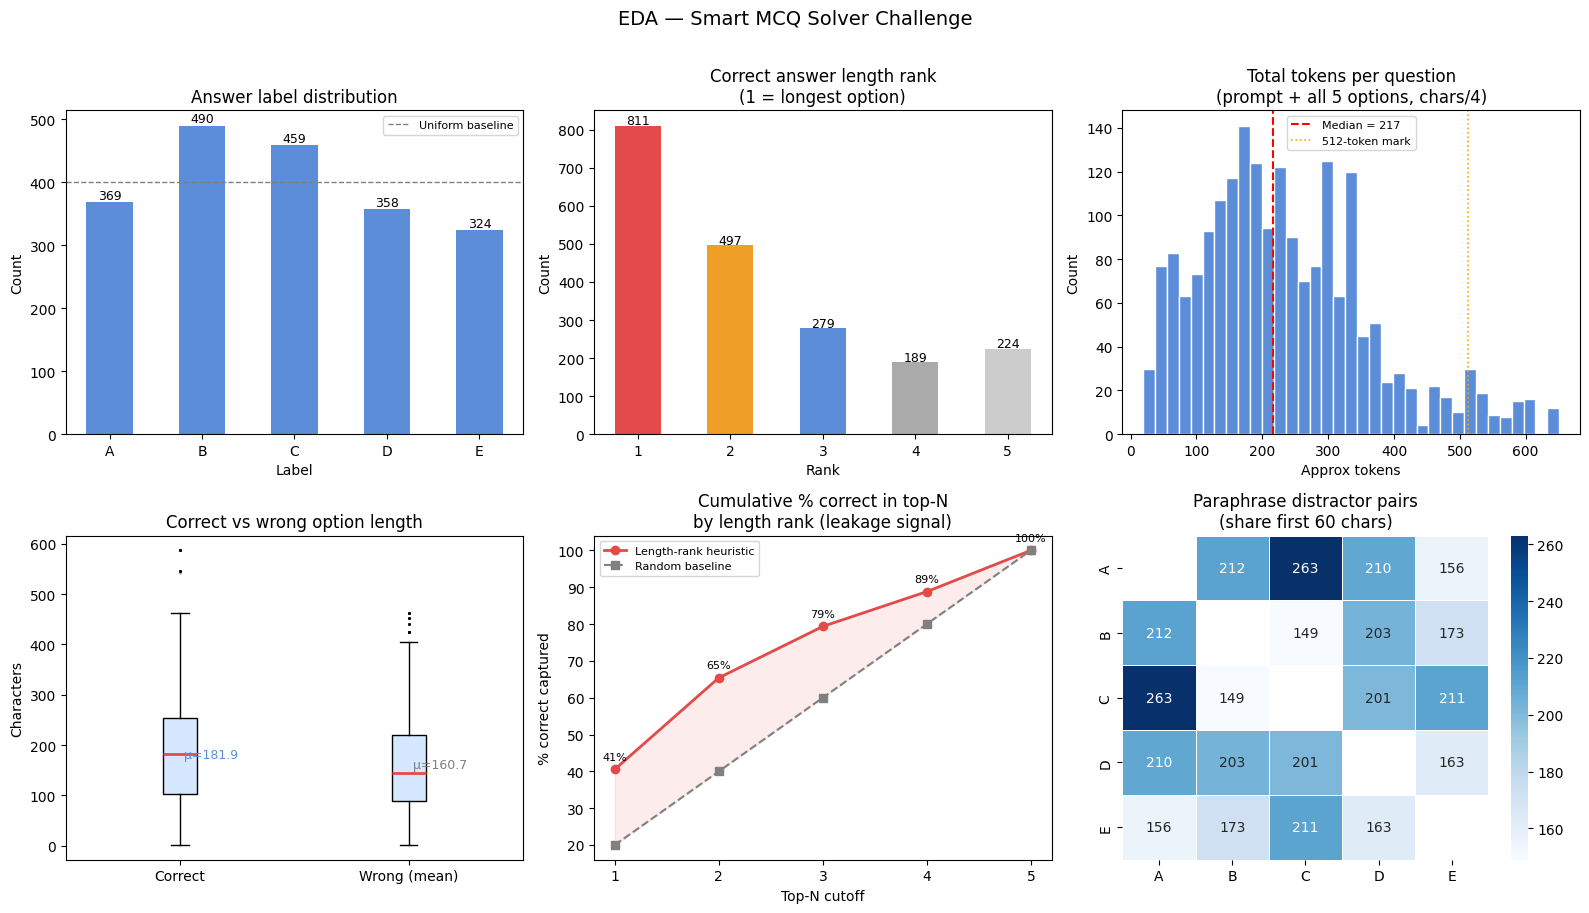

✓ EDA complete.


In [5]:
# ===========================================================
# EDA — Smart MCQ Solver  |  DL / GenAI notebook
# ===========================================================

OPTIONS = ["A", "B", "C", "D", "E"]
train_df = train_dataset.copy()

# -----------------------------------------------------------
# feature engineering
# -----------------------------------------------------------
for c in OPTIONS:
    train_df[f"{c}_len"] = train_df[c].str.len()

train_df["prompt_tokens"] = (train_df["prompt"].str.len() / 4).round().astype(int)  # 4 is approximate token length in english language normally
train_df["total_tokens"]  = (
    train_df["prompt_tokens"]
    + sum((train_df[f"{c}_len"] / 4).round().astype(int) for c in OPTIONS)
)

def correct_option_rank_by_length(row):
    lengths = {c: row[f"{c}_len"] for c in OPTIONS}
    return sorted(lengths, key=lengths.get, reverse=True).index(row["answer"]) + 1

train_df["correct_option_rank_by_length"] = train_df.apply(correct_option_rank_by_length, axis=1)
train_df["correct_option_len"] = train_df.apply(lambda r: r[f"{r['answer']}_len"], axis=1)
train_df["mean_wrong_len"] = train_df.apply(
    lambda r: np.mean([r[f"{c}_len"] for c in OPTIONS if c != r["answer"]]), axis=1
)

# -----------------------------------------------------------
# overview print
# -----------------------------------------------------------
print("=" * 52)
print("  DATASET OVERVIEW")
print("=" * 52)
print(f"  Rows                  : {len(train_df):,}")
print(f"  Nulls                 : {train_df.isnull().sum().sum()}")
print(f"  Duplicate prompts     : {train_df.duplicated('prompt').sum()}")
print(f"  Unique option texts   : {pd.concat([train_df[c] for c in OPTIONS]).nunique():,} / {len(train_df)*5:,}")
print()
print("  Answer distribution:")
for label, cnt in train_df["answer"].value_counts().reindex(OPTIONS).items():
    print(f"    {label}  {cnt}  ({cnt/len(train_df)*100:.1f}%)")
print()
print(f"  Correct option avg len    : {train_df['correct_option_len'].mean():.1f} chars")
print(f"  Wrong  option avg len     : {train_df['mean_wrong_len'].mean():.1f} chars")
print(f"  longest option is correct : {(train_df['correct_option_rank_by_length']==1).mean()*100:.1f}% of the time")
print(f"  Avg total tokens/question : {train_df['total_tokens'].mean():.0f}  (max {train_df['total_tokens'].max()})")
print("=" * 52)

# -----------------------------------------------------------
# figures
# -----------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
fig.suptitle("EDA — Smart MCQ Solver Challenge", fontsize=14, y=1.01)

# 1. answer label distribution
ans_counts = train_df["answer"].value_counts().reindex(OPTIONS)
axes[0, 0].bar(OPTIONS, ans_counts.values, color="#5B8DD9", width=0.5)
axes[0, 0].axhline(len(train_df) / 5, color="gray", lw=1, linestyle="--", label="Uniform baseline")
axes[0, 0].set_title("Answer label distribution")
axes[0, 0].set_xlabel("Label")
axes[0, 0].set_ylabel("Count")
axes[0, 0].legend(fontsize=8)
for i, v in enumerate(ans_counts.values):
    axes[0, 0].text(i, v + 5, str(v), ha="center", fontsize=9)

# 2. correct answer length rank
rank_counts = train_df["correct_option_rank_by_length"].value_counts().sort_index()
axes[0, 1].bar(rank_counts.index, rank_counts.values,
               color=["#E24B4A", "#EF9F27", "#5B8DD9", "#AAAAAA", "#CCCCCC"], width=0.5)
axes[0, 1].set_title("Correct answer length rank\n(1 = longest option)")
axes[0, 1].set_xlabel("Rank")
axes[0, 1].set_ylabel("Count")
for x, v in zip(rank_counts.index, rank_counts.values):
    axes[0, 1].text(x, v + 4, str(v), ha="center", fontsize=9)

# 3. total tokens per question
axes[0, 2].hist(train_df["total_tokens"], bins=35, color="#5B8DD9", edgecolor="white", lw=0.4)
axes[0, 2].axvline(train_df["total_tokens"].median(), color="red", lw=1.5,
                   linestyle="--", label=f"Median = {train_df['total_tokens'].median():.0f}")
axes[0, 2].axvline(512, color="orange", lw=1.2, linestyle=":", label="512-token mark")
axes[0, 2].set_title("Total tokens per question\n(prompt + all 5 options, chars/4)")
axes[0, 2].set_xlabel("Approx tokens")
axes[0, 2].set_ylabel("Count")
axes[0, 2].legend(fontsize=8)

# 4. correct vs wrong option length boxplot
axes[1, 0].boxplot(
    [train_df["correct_option_len"].values, train_df["mean_wrong_len"].values],
    labels=["Correct", "Wrong (mean)"],
    patch_artist=True,
    boxprops=dict(facecolor="#D6E8FF"),
    medianprops=dict(color="#E24B4A", linewidth=2),
    flierprops=dict(marker=".", markersize=2, alpha=0.3),
)
axes[1, 0].set_title("Correct vs wrong option length")
axes[1, 0].set_ylabel("Characters")
for x, col, val in [(1, "#5B8DD9", train_df["correct_option_len"].mean()),
                    (2, "gray",    train_df["mean_wrong_len"].mean())]:
    axes[1, 0].text(x, val, f" μ={val:.1f}", va="center", fontsize=9, color=col)

# 5. cumulative top-N by length rank vs random
cumulative = [(train_df["correct_option_rank_by_length"] <= n).mean() * 100 for n in range(1, 6)]
random_baseline = [n / 5 * 100 for n in range(1, 6)]
axes[1, 1].plot(range(1, 6), cumulative, "o-", color="#E24B4A", lw=2, label="Length-rank heuristic")
axes[1, 1].plot(range(1, 6), random_baseline, "s--", color="gray", lw=1.5, label="Random baseline")
axes[1, 1].fill_between(range(1, 6), random_baseline, cumulative, alpha=0.1, color="#E24B4A")
axes[1, 1].set_title("Cumulative % correct in top-N\nby length rank (leakage signal)")
axes[1, 1].set_xlabel("Top-N cutoff")
axes[1, 1].set_ylabel("% correct captured")
axes[1, 1].set_xticks(range(1, 6))
axes[1, 1].legend(fontsize=8)
for x, y in zip(range(1, 6), cumulative):
    axes[1, 1].annotate(
        f"{y:.0f}%", 
        (x, y), xytext=(0, 7),
        textcoords="offset points",
        ha="center", fontsize=8
    )

# 6. pairwise paraphrase distractor heatmap
# for every pair of options across all 2000 questions,
# how many times they share the same first 100 characters.
sim = np.zeros((5, 5))
for i, a in enumerate(OPTIONS):
    for j, b in enumerate(OPTIONS):
        if i != j:
            sim[i][j] = (train_df[a].str[:100] == train_df[b].str[:100]).sum()

# plotting similarity matrix
sns.heatmap(sim, annot=True, fmt=".0f", ax=axes[1, 2],
            xticklabels=OPTIONS, yticklabels=OPTIONS,
            cmap="Blues", mask=np.eye(5, dtype=bool),
            linewidths=0.4, annot_kws={"size": 10})
axes[1, 2].set_title("Paraphrase distractor pairs\n(share first 60 chars)")

plt.tight_layout()
plt.savefig("eda_mcq.png", dpi=150, bbox_inches="tight")
plt.show()
print("✓ EDA complete.")

In [6]:
# ===========================================================
# Dummy submission — length-rank heuristic based on EDA
# MAP@3: predict the 3 longest options per question
# ===========================================================

# ===========================================================
# Dummy submission — length-rank heuristic
# ===========================================================
# EDA finding: correct answer is the longest option in 40.6% of questions.
# Picking top-3 by length captures the correct answer 79.3% of the time.
#
# Note: this works because the dataset has a length bias (correct answers
# are consistently longer than distractors). A real model must learn
# semantics and score well beyond this heuristic.
# ===========================================================

# OPTIONS = ["A", "B", "C", "D", "E"]
# def top3_by_length(row):
#     lengths = {c: len(row[c]) for c in OPTIONS}
#     ranked  = sorted(lengths, key=lengths.get, reverse=True)
#     return " ".join(ranked[:3])   # e.g. "B C A"

# dummy_submission = pd.DataFrame({
#     "ID":         test_dataset["id"],
#     "Prediction": test_dataset.apply(top3_by_length, axis=1),
# })

# dummy_submission.to_csv("submission.csv", index=False)
# print(dummy_submission.head(10).to_string(index=False))
# print(f"\n✓ dummy submission.csv saved  ({len(dummy_submission)} rows)")

## NLP Foundation & Semantic Similarity (Milestone 1 Approach)
### Tasks

**1. Text Cleaning, Tokenization & Handling Missing Data**
- Check for missing/null values in train and test sets
- Clean text: lowercase, strip whitespace, remove extra spaces
- Two tokenization strategies: TF-IDF (joined string) and Word2Vec (list of tokens, stopwords kept)

**2. Embeddings using Baseline Models**
- **TF-IDF** — sparse embeddings; represents each text as a weighted word-frequency vector over the vocabulary
- **Word2Vec** — dense embeddings; trains a neural network on (prompt + options) to produce 100-dimensional word vectors, sentence vector = mean pooling of word vectors

**3. Cosine Similarity between Prompt and Options**
- For each row, compute cosine similarity between the prompt vector and each of the 5 option vectors (A–E)
- Rank options by similarity score → top 3 = prediction
- Cosine similarity measures the angle between two vectors — 1.0 = identical direction, 0.0 = orthogonal

**4. MAP@3 — Metric & Concept**
- MAP@3 (Mean Average Precision at 3) — competition metric
- For each question, predict 3 options in ranked order:
  - Correct answer at rank 1 → score `1/1 = 1.0`
  - Correct answer at rank 2 → score `1/2 = 0.5`
  - Correct answer at rank 3 → score `1/3 = 0.33`
  - Not in top 3 → score `0.0`
- MAP@3 = mean of these scores across all questions

In [7]:
# import nltk
# from nltk.corpus import stopwords
# from nltk.tokenize import word_tokenize

# from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
# from sklearn.metrics.pairwise import cosine_similarity

# from gensim.models import Word2Vec

In [8]:
# ===============================================================================
# MAP@3 Evaluation - MAP@3 (Mean Average Precision at 3) — the competition metric
# ====================================================================================
# For each question, we predict 3 options in ranked order.
# The score is:
#   1/1 = 1.0   if correct answer is rank 1
#   1/2 = 0.5   if correct answer is rank 2
#   1/3 = 0.33  if correct answer is rank 3
#   0.0         if correct answer is not in top 3
#
# MAP@3 = mean of these scores across all questions.

def apk(actual, predicted, k=3):
    predicted = predicted[:k]
    if actual not in predicted:
        return 0.0
    return 1.0 / (predicted.index(actual) + 1)

def mapk(df, pred_col):
    return df.apply(lambda row: apk(row['answer'], row[pred_col].split()), axis=1).mean()

In [9]:
# train_df = train_dataset.copy()    # Handles missing values & texts from the training dataset if exists

# print("=== standard NaN check =======")
# print(train_df.isna().sum())

# placeholders = {"n/a", "na", "null", "none", "nan", "-", "--", "?"}

# def text_missing(col):
#     if col.dtype != "object":          # ← skip numeric columns
#         return pd.Series({
#             "is_nan": col.isna().sum(),
#             "empty_string": 0,
#             "placeholder": 0,
#         })
#     s = col.str.strip()
#     return pd.Series({
#         "is_nan": col.isna().sum(),
#         "empty_string": (s == "").sum(),
#         "placeholder": s.str.lower().isin(placeholders).sum(),
#     })

# print("\nText-quality audit:")
# print(train_df.apply(text_missing).T)

In [10]:
# # ============================================================
# # Text Cleaning
# # ============================================================
# #
# # What we clean:
# #   - Leading / trailing whitespace
# #   - Consecutive internal spaces (double-spaces, tab artifacts)
# #
# # What we keep as-is:
# #   - Paraphrase prefixes (e.g. "Pick the best possible answer:")
# #     -> 38% of test prompts have NO prefix, so stripping it from
# #        train would create a train/test mismatch
# #   - Non-ASCII scientific symbols (ρ̂, μ, →)
# #     -> these are semantically meaningful, not noise

# for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
#     train_df[col] = train_df[col].str.strip().str.replace(r'\s+', ' ', regex=True)

# print("Cleaning done — sample prompt:")
# print(train_df['prompt'].iloc[0])

In [11]:
# # ============================================================
# # Tokenization
# # ============================================================
# #
# # Two tokenization strategies — one per model:
# #
# #              TF-IDF                                 Word2Vec
# #   Output:    joined string                          list of tokens
# #   Stopwords: removed (reduces noise)                kept (W2V needs context)
# #   Why:       .fit_transform() expects a string     .train() expects list of lists
# # ========================================================================================                

# # _stdout = sys.stdout; sys.stdout = io.StringIO()  # temporarily silence nltk's verbose download messages
# # nltk.download('punkt'); nltk.download('punkt_tab'); nltk.download('stopwords')
# # sys.stdout = _stdout

# stop_words = set(stopwords.words('english'))

# def tokenize(text, remove_stopwords=False):
#     text = text.lower()
#     text = re.sub(r'[^a-z0-9\s]', ' ', text)   # remove punctuation, keep alphanumeric
#     text = re.sub(r'\s+', ' ', text).strip()    # normalise whitespace
#     tokens = word_tokenize(text)
#     if remove_stopwords:
#         tokens = [t for t in tokens if t not in stop_words]
#     return tokens

# # TF-IDF: tokens joined back to string (vectorizer expects string input)
# for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
#     train_df[f'{col}_tfidf'] = train_df[col].apply(
#         lambda x: ' '.join(tokenize(x, remove_stopwords=True))
#     )

# # Word2Vec: keep as list of tokens (model expects list of lists)
# for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
#     train_df[f'{col}_w2v'] = train_df[col].apply(
#         lambda x: tokenize(x, remove_stopwords=False)
#     )

# print("Tokenization complete.")
# print("TF-IDF sample :", train_df['prompt_tfidf'].iloc[0])
# print("W2V sample :", train_df['prompt_w2v'].iloc[0])

In [12]:
# # ============================================================
# # Embeddings & Cosine Similarity
# # ============================================================

# # ------------------------------------------------------------
# # 4a. TF-IDF (Sparse Embeddings)
# # ------------------------------------------------------------
# # TF-IDF represents each text as a sparse vector where each dimension is a vocabulary word.
# # The value is high for words that are frequent in this text 
# # but rare across all texts — so domain-specific terms
# # (e.g. "metallicity", "eigenstate") get high weight.
# #
# # We fit the vectorizer on ALL text (prompts + all options)
# # so the vocabulary covers everything.............
# # ====================================================================

# # Cosine similarity: prompt vs each option → pick top 3
# def get_top3_tfidf(row):
#     prompt_vec = vectorizer.transform([row['prompt_tfidf']])
#     scores = {
#         opt: cosine_similarity(prompt_vec, vectorizer.transform([row[f'{opt}_tfidf']]))[0][0]
#         for opt in ['A','B','C','D','E']
#     }
#     return ' '.join(sorted(scores, key=scores.get, reverse=True)[:3])
    
# # Fit on all text to build a shared vocabulary
# all_text = pd.concat([train_df[f'{col}_tfidf'] for col in ['prompt','A','B','C','D','E']])
# vectorizer = TfidfVectorizer()
# vectorizer.fit(all_text)

# print(f"TF-IDF vocabulary size: {len(vectorizer.vocabulary_):,} terms")

# train_df['tfidf_pred'] = train_df.apply(get_top3_tfidf, axis=1)
# print("\nSample predictions (actual answer | tfidf_pred):")
# print(train_df[['answer','tfidf_pred']].head(5).to_string())

In [13]:
# # ------------------------------------------------------------
# # 4b. Word2Vec (Dense Embeddings)
# # ------------------------------------------------------------
# # Word2Vec trains a neural network to predict surrounding words,
# # producing dense 100-dim vectors where semantically similar words are geometrically close (e.g. "velocity" near "speed").
# #
# # Since Word2Vec gives word vectors (not sentence vectors), we use mean pooling — 
# # average all word vectors in a sentence to get one sentence vector.
# # ======================================================================

# # Train on all sentences (prompt + all options) — more data = better vectors
# all_sentences = []
# for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
#     all_sentences.extend(train_df[f'{col}_w2v'].tolist())

# w2v_model = Word2Vec(
#     sentences=all_sentences,
#     vector_size=100,   # embedding dimension
#     window=5,          # context window size
#     min_count=1,       # include all words (small dataset)
#     workers=4,
#     seed=42
# )
# print(f"Word2Vec vocab size : {len(w2v_model.wv):,} words")
# print(f"Vector dimensions  : {w2v_model.vector_size}")

# # Mean pooling: average word vectors → sentence vector
# def sentence_vector(tokens, model):
#     vecs = [model.wv[t] for t in tokens if t in model.wv]
#     return np.mean(vecs, axis=0) if vecs else np.zeros(model.vector_size)
    
# # Cosine similarity: prompt vs each option → pick top 3
# def get_top3_w2v(row):
#     p_vec = sentence_vector(row['prompt_w2v'], w2v_model).reshape(1, -1)   # prompt vector
#     scores = {
#         opt: cosine_similarity(p_vec, sentence_vector(row[f'{opt}_w2v'], w2v_model).reshape(1,-1))[0][0]
#         for opt in ['A','B','C','D','E']
#     }
#     return ' '.join(sorted(scores, key=scores.get, reverse=True)[:3])

# train_df['w2v_pred'] = train_df.apply(get_top3_w2v, axis=1)
# print("\nSample predictions (actual answer | w2v_pred):")
# print(train_df[['answer','w2v_pred']].head(5).to_string())

In [14]:
# map3_tfidf = mapk(train_df, 'tfidf_pred')
# map3_w2v = mapk(train_df, 'w2v_pred')
# print(f"TF-IDF MAP@3 : {map3_tfidf:.4f}")
# print(f"Word2Vec MAP@3 : {map3_w2v:.4f}")
# print(" ")

# models = ['TF-IDF', 'Word2Vec']
# scores = [map3_tfidf, map3_w2v]
# colors = ['#5B8DD9', '#E24B4A']

# # ------ Length-rank baseline (EDA dummy submission) -------------
# train_df['length_pred'] = train_df.apply(top3_by_length, axis=1)
# map3_length = mapk(train_df, 'length_pred')
# print(f"Length baseline MAP@3 : {map3_length:.4f}")
# print(f"TF-IDF          MAP@3 : {map3_tfidf:.4f}")
# print(f"Word2Vec        MAP@3 : {map3_w2v:.4f}")

# # ----------- Plot -------------------
# all_models  = ['Length\nBaseline', 'TF-IDF', 'Word2Vec']
# all_scores  = [map3_length, map3_tfidf, map3_w2v]
# all_colors  = ['#AAAAAA', '#5B8DD9', '#E24B4A']

# fig, ax = plt.subplots(figsize=(6, 4))
# fig.suptitle("Milestone 1 — TF-IDF vs Word2Vec (MAP@3)", fontsize=13)

# bars = ax.bar(all_models, all_scores, color=all_colors, width=0.4, zorder=3)
# ax.axhline(map3_length, color='gray', lw=1.5, linestyle='--',
#            label=f'Length baseline ({map3_length:.4f})')
# ax.set_ylim(0, max(all_scores) * 1.3)
# ax.set_ylabel('MAP@3')
# ax.set_title('MAP@3 Score')
# ax.legend(fontsize=9)
# ax.grid(axis='y', alpha=0.3, zorder=0)

# for bar, score in zip(bars, all_scores):
#     ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
#              f'{score:.4f}', ha='center', fontsize=11, fontweight='bold')

# plt.tight_layout()
# plt.show()

# # ------------ Summary ------------------
# winner = max(zip(all_scores, all_models), key=lambda x: x[0])[1].replace('\n', ' ')
# print(f"\n{'='*47}")
# print(f"  Milestone 1 Summary")
# print(f"{'='*47}")
# print(f"  Length baseline MAP@3 : {map3_length:.4f}  ← EDA dummy")
# print(f"  TF-IDF          MAP@3 : {map3_tfidf:.4f}")
# print(f"  Word2Vec        MAP@3 : {map3_w2v:.4f}")
# print(f"  Best model            : {winner}")
# print(f"{'='*47}")
# print(" ")
# print(
#     "\n📊 Key Insight from Milestone 1:"
#     "\n---------------------------------------------"
#     "\n  Both TF-IDF and Word2Vec scored BELOW the dummy case(length-rank heuristic)"
#     "\n  length-rank heuristic (0.57 vs ~0.31-0.34)."
#     "\n"
#     "\n  Why? Science MCQ prompts and answers share few"
#     "\n  keywords — e.g. 'What is the metallicity?' vs"
#     "\n  '8 times less than the Sun' — zero word overlap."
#     "\n  TF-IDF and Word2Vec trained on ~2000 rows cannot"
#     "\n  bridge this semantic gap."
#     "\n"
#     "\n  This motivates Milestone 2: pre-trained sentence-"
#     "\n  transformers (all-MiniLM, sentence-BERT) that"
#     "\n  understand paraphrasing and domain semantics"
#     "\n  should decisively beat even the length baseline."
#     "\n-----------------------------------------------"
# )

## Milestone 1 Q/A

In [15]:
# OPTIONS = ['A', 'B', 'C', 'D', 'E']
# train_df = train_dataset.copy()

# # -------- Q1: Frequency distribution of correct answers ---------
# freq = train_df['answer'].value_counts()
# print("=== Q1: Answer Frequency Distribution ===")
# print(freq.to_string())
# most_frequent_count  = freq.iloc[0]
# least_frequent_count = freq.iloc[-1]
# q1_answer = most_frequent_count + least_frequent_count
# print(f"\nMost frequent  : {freq.index[0]}  →  {most_frequent_count}")
# print(f"Least frequent : {freq.index[-1]}  →  {least_frequent_count}")
# print(f"Sum (Q1 answer): {q1_answer}")

# # --------- Q2: Unique words in cleaned prompt column ------------------
# def clean_text(text):
#     text = str(text).lower()
#     text = text.translate(str.maketrans('', '', string.punctuation))
#     return text

# cleaned_prompts = train_df['prompt'].apply(clean_text)
# all_words = set()
# for prompt in cleaned_prompts:
#     all_words.update(prompt.split())

# q2_answer = len(all_words)
# print(f"\n=== Q2: Vocabulary size (unique words in cleaned prompts) ===")
# print(f"Vocabulary size: {q2_answer}")

# # -------- Q3: Words left after stop word removal for Row ID 1 -----------
# row1_prompt = cleaned_prompts.iloc[0]   # Row ID 1 = index 0
# row1_words  = row1_prompt.split()
# filtered    = [w for w in row1_words if w not in ENGLISH_STOP_WORDS]
# q3_answer   = len(filtered)
# print(f"\n=== Q3: Words in Row ID 1 prompt after stop word removal ===")
# print(f"Cleaned prompt of row 1 : {row1_prompt}")
# print(f"Words before removing stop words : {row1_words}")
# print(f"Words after removing stop words : {filtered}")
# print(f"Count (Q3 answer): {q3_answer}")

# # ── Q4: TF-IDF vocabulary size (prompt + all options combined) ─────────────────
# all_texts = []
# for col in ['prompt', 'A', 'B', 'C', 'D', 'E']:
#     all_texts.extend(train_df[col].tolist())

# vectorizer_q4 = TfidfVectorizer(stop_words='english')
# vectorizer_q4.fit(all_texts)
# q4_answer = len(vectorizer_q4.vocabulary_)
# print(f"\n=== Q4: TF-IDF vocabulary size (all prompts + options) ===")
# print(f"Feature columns (Q4 answer): {q4_answer}")

# # ------- Q5: Cosine similarity between prompt and option A for Row ID 1 ----------
# row1 = train_df.iloc[0]
# vecs = vectorizer_q4.transform([row1['prompt'], row1['A']])
# q5_answer = cosine_similarity(vecs[0], vecs[1])[0][0]
# print(f"\n=== Q5: Cosine similarity — Row ID 1, prompt vs option A ===")
# print(f"Prompt   : {row1['prompt']}")
# print(f"Option A : {row1['A']}")
# print(f"Cosine similarity (Q5 answer): {q5_answer:.4f}")

# # -------- Q6: % of rows where highest cosine sim option = correct answer ---------
# def tfidf_top1(row):
#     texts = [row['prompt']] + [row[o] for o in OPTIONS]
#     vecs = vectorizer_q4.transform(texts)
#     prompt_vec = vecs[0]
#     sims = {o: cosine_similarity(prompt_vec, vecs[i+1])[0][0] for i, o in enumerate(OPTIONS)}
#     return max(sims, key=sims.get)

# train_df['tfidf_top1'] = train_df.apply(tfidf_top1, axis=1)
# q6_answer = (train_df['tfidf_top1'] == train_df['answer']).mean() * 100
# print(f"\n=== Q6: % rows where top TF-IDF cosine sim = correct answer ===")
# print(f"Accuracy (Q6 answer): {q6_answer:.2f}%")

# # --------- Q7: MAP@3 if ground truth = C and prediction = C A B -----------------
# q7_answer = 1.0 / ((['C', 'A', 'B'].index('C')) + 1)
# print(f"\n=== Q7: MAP@3 — ground truth C, prediction C A B ===")
# print(f"C is at position 1 → 1/1 = {q7_answer:.4f}")

# # ---------- Q8: MAP@3 if ground truth = B and prediction = D B E -----------
# q8_answer = 1.0 / ((['D', 'B', 'E'].index('B')) + 1)
# print(f"\n=== Q8: MAP@3 — ground truth B, prediction D B E ===")
# print(f"B is at position 2 → 1/2 = {q8_answer:.4f}")

# # ----------- Q9: Majority class baseline MAP@3 ------------------
# top3_answers = freq.index[:3].tolist()   # top 3 most frequent answer letters
# static_pred = ' '.join(top3_answers)
# train_df['majority_pred'] = static_pred

# q9_answer = mapk(train_df, 'majority_pred')
# print(f"\n=== Q9: Majority class baseline MAP@3 ===")
# print(f"Static prediction for every row: '{static_pred}'")
# print(f"MAP@3 (Q9 answer): {q9_answer:.4f}")

# # ------ Q10: TF-IDF pipeline MAP@3 across entire train set -----------
# # (reuses map3_tfidf already computed above — same pipeline)
# print(f"\n=== Q10: TF-IDF pipeline MAP@3 (entire train set) ===")
# print(f"MAP@3 (Q10 answer): {map3_tfidf:.4f}")

# # -------------- Summary --------------
# print("\n" + "="*55)
# print("ANSWERS SUMMARY")
# print("="*55)
# print(f"  Q1  — most + least frequent count sum : {q1_answer}")
# print(f"  Q2  — vocabulary size (prompts)       : {q2_answer}")
# print(f"  Q3  — words after stopword removal    : {q3_answer}")
# print(f"  Q4  — TF-IDF feature columns          : {q4_answer}")
# print(f"  Q5  — cosine sim row1 prompt vs A     : {q5_answer:.4f}")
# print(f"  Q6  — top-1 accuracy TF-IDF           : {q6_answer:.2f}%")
# print(f"  Q7  — MAP@3 (C predicted as C A B)    : {q7_answer:.4f}")
# print(f"  Q8  — MAP@3 (B predicted as D B E)    : {q8_answer:.4f}")
# print(f"  Q9  — majority class baseline MAP@3   : {q9_answer:.4f}")
# print(f"  Q10 — TF-IDF pipeline MAP@3           : {map3_tfidf:.4f}")
# print("="*55)

## Milestone 2: Pretrained Transformer Approaches

We leverage two HuggingFace libraries for this milestone:

| Library | Purpose |
|---|---|
| `transformers` | Model architectures, tokenizers, and pipelines |
| `sentence-transformers` | Wraps transformer models to produce fixed-size sentence embeddings directly |

### Approach 1 — BERT / RoBERTa (CLS Pooling)
Fine-tune / extract embeddings using `[CLS]` token pooling from BERT/RoBERTa.

### Approach 2 — Sentence Transformers (SBERT)
Use `sentence-transformers` (e.g., `all-MiniLM-L6-v2`) for direct sentence embeddings and similarity scoring.

### Approach 3 — Zero-Shot Classification
Use a zero-shot pipeline (e.g., BART-MNLI) to score answer options without task-specific fine-tuning.

### Evaluation & Summary
Compare all three approaches on MAP@3, summarize results in a table.

### Generate Submission
Produce the final `submission.csv` in the required format.

In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel, AutoModelForSeq2SeqLM
from sentence_transformers import SentenceTransformer, util
from transformers import pipeline
from datasets import load_dataset
from transformers import pipeline as hf_pipeline

SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

print("torch version :", torch.__version__)
print("CUDA available :", torch.cuda.is_available())
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device :", device)

train_df = train_dataset.copy()
test_df = test_dataset.copy()

torch version : 2.10.0+cu128
CUDA available : True
Using device : cuda


In [17]:
# # Milestone 2A (loading a pretrained bert model - roberta-base)

# BERT_MODEL = "roberta-base"   # pretrained model name

# bert_tokenizer = AutoTokenizer.from_pretrained(BERT_MODEL)
# bert_model = AutoModel.from_pretrained(BERT_MODEL)      # downloads the pretrained weights
# bert_model.eval()   # disables dropouts - freeze the behavior — no dropout, no randomness

# if torch.cuda.is_available():
#     bert_model = bert_model.to(device)

# print(f"Loaded : {BERT_MODEL}")
# print(f"Layers : {bert_model.config.num_hidden_layers}")
# print(f"Hidden : {bert_model.config.hidden_size}")
# print(f"Params : {sum(p.numel() for p in bert_model.parameters()):,}")

In [18]:
# def get_cls_embeddings(texts, tokenizer, model, batch_size=32):
#     all_vecs = []
#     for i in range(0, len(texts), batch_size):
#         batch = texts[i: i + batch_size]
#         encoded = tokenizer(
#             batch,
#             padding=True,
#             truncation=True,
#             max_length=128,
#             return_tensors='pt'
#         )

#         if torch.cuda.is_available():
#             encoded = {k: v.to(device) for k, v in encoded.items()}

#         with torch.no_grad():
#             output = bert_model(**encoded)

#         # output.last_hidden_state shape: (batch, seq_len, hidden_size)
#         # index 0 along seq_len = [CLS] token
#         cls_vecs = output.last_hidden_state[:, 0, :]   # (batch, hidden_size)
#         all_vecs.append(cls_vecs.cpu().numpy())  # cls vector from each batch is appended to all vecs

#     return np.vstack(all_vecs)   # (N, hidden_size)

# sample_vec = get_cls_embeddings(["What is the speed of light?"], bert_tokenizer, bert_model)
# print(f"CLS vector shape : {sample_vec.shape}")   # (1, 768)
# print(f"First 5 values   : {sample_vec[0][:5]}")

In [19]:
# OPTIONS = ['A', 'B', 'C', 'D', 'E']

# # Encode train set
# print("Encoding train prompts...")
# train_bert_prompt = get_cls_embeddings(train_df['prompt'].tolist(), bert_tokenizer, bert_model)

# train_bert_options = {}
# for opt in OPTIONS:
#     print(f"Encoding train option {opt}...")
#     train_bert_options[opt] = get_cls_embeddings(train_df[opt].tolist(), bert_tokenizer, bert_model)

# # Encode test set
# # print("\nEncoding test prompts...")
# # test_bert_prompt = get_cls_embeddings(test_df['prompt'].tolist(), bert_tokenizer, bert_model)

# # test_bert_options = {}
# # for opt in OPTIONS:
# #     print(f"Encoding test option {opt}...")
# #     test_bert_options[opt] = get_cls_embeddings(test_df[opt].tolist(), bert_tokenizer, bert_model)

# print("\nAll BERT embeddings done.")
# print(f"train_bert_prompt shape : {train_bert_prompt.shape}")

In [20]:
# def bert_top3(prompt_vec, option_vecs_dict):
#     """Given CLS vectors, rank options by cosine similarity to prompt."""
#     scores = {
#         opt: cosine_similarity(
#             prompt_vec.reshape(1, -1),
#             option_vecs_dict[opt].reshape(1, -1)
#         )[0][0]
#         for opt in OPTIONS
#     }
#     return ' '.join(sorted(scores, key=scores.get, reverse=True)[:3])

# # Train predictions (for MAP@3)
# train_df['bert_pred'] = [
#     bert_top3(
#         train_bert_prompt[i],
#         {opt: train_bert_options[opt][i] for opt in OPTIONS}
#     )
#     for i in range(len(train_df))
# ]

# # # Test predictions (for submission)
# # test_df['bert_pred'] = [
# #     bert_top3(
# #         test_bert_prompt[i],
# #         {opt: test_bert_options[opt][i] for opt in OPTIONS}
# #     )
# #     for i in range(len(test_df))
# # ]

# map3_bert = mapk(train_df, 'bert_pred')
# print(f"RoBERTa (CLS pooling) MAP@3 : {map3_bert:.4f}")    # 0.3336
# print("\nSample predictions (answer | bert_pred):")
# print(train_df[['answer', 'bert_pred']].head(5).to_string())

In [21]:
# # Milestone 2B (sentence transformers approach)

# sbert_model = SentenceTransformer(
#     'sentence-transformers/all-MiniLM-L6-v2',
#     device=device
# )
# print("Model loaded:", sbert_model)
# print("Embedding dimension:", sbert_model.get_sentence_embedding_dimension())

In [22]:
# # ---------- ENCODE ALL EMBEDDINGS (SBERT) -----------
# OPTIONS = ['A', 'B', 'C', 'D', 'E']
# print("Encoding train prompts...")
# train_prompt_emb_sbert = sbert_model.encode(train_df['prompt'].tolist(), batch_size=64,
#                                              show_progress_bar=True, convert_to_numpy=True)
# train_option_emb = {}
# for opt in OPTIONS:
#     print(f"Encoding train option {opt}...")
#     train_option_emb[opt] = sbert_model.encode(train_df[opt].tolist(), batch_size=64,
#                                                 show_progress_bar=False, convert_to_numpy=True)
# # Encode test set
# # print("\nEncoding test prompts...")
# # test_prompt_emb_sbert = sbert_model.encode(test_df['prompt'].tolist(), batch_size=64,
# #                                             show_progress_bar=True, convert_to_numpy=True)
# # test_option_emb = {}
# # for opt in OPTIONS:
# #     print(f"Encoding test option {opt}...")
# #     test_option_emb[opt] = sbert_model.encode(test_df[opt].tolist(), batch_size=64,
# #                                                show_progress_bar=False, convert_to_numpy=True)
# print("\nAll SBERT embeddings done.")
# print(f"train_prompt_emb_sbert shape : {train_prompt_emb_sbert.shape}")

In [23]:
# def sbert_top3(prompt_vec, option_vecs):
#     scores = {
#         opt: cosine_similarity(prompt_vec.reshape(1, -1), option_vecs[opt].reshape(1, -1))[0][0]
#         for opt in OPTIONS
#     }
#     return ' '.join(sorted(scores, key=scores.get, reverse=True)[:3])

# train_df['sbert_pred'] = [
#     sbert_top3(train_prompt_emb_sbert[i], {opt: train_option_emb[opt][i] for opt in OPTIONS})
#     for i in range(len(train_df))
# ]

# # test_df['sbert_pred'] = [
# #     sbert_top3(test_prompt_emb_sbert[i], {opt: test_option_emb[opt][i] for opt in OPTIONS})
# #     for i in range(len(test_df))
# # ]

# map3_sbert = mapk(train_df, 'sbert_pred')
# print(f"sbert MAP@3 : {map3_sbert:.4f}")
# print("\nSample SBERT predictions (answer | sbert_pred):")
# print(train_df[['answer', 'sbert_pred']].head(5).to_string())

In [24]:
# # Milestone 2C (zero shot classification - pretrained NLI models)

# """ Concept: Natural Language Inference (NLI) models are trained to predict 
#              whether a *hypothesis* is entailed by, contradicts, or is neutral to a *premise*.

# We repurpose this:
# - **Premise** = the MCQ prompt (the question)
# - **Hypothesis** = each answer option

# The model gives a probability that the option is "entailed" by the question — 
# which approximates "how well does this option answer the question?".

# This is **zero-shot** because we never fine-tune on MCQ data — 
# we're using the model's pre-trained understanding of language entailment """

# zs_pipeline = pipeline(
#     "zero-shot-classification",
#     model="facebook/bart-large-mnli",
#     device=0 if torch.cuda.is_available() else -1
# )
# print("Zero-shot pipeline loaded.")

In [25]:
# def zeroshot_top3(prompt, options_dict):
#     """
#     options_dict: {'A': text, 'B': text, ...}
#     Returns a string like 'B A D' (top 3 by entailment score)
#     """
#     candidate_labels = list(options_dict.values())
#     result = zs_pipeline(prompt, candidate_labels, multi_label=False)

#     label_to_opt = {v: k for k, v in options_dict.items()}
#     ranked_opts = [label_to_opt[label] for label in result['labels'][:3]]
#     return ' '.join(ranked_opts)
    

# print("Running zero-shot classification on train set")
# train_df['zs_pred'] = [
#     zeroshot_top3(
#         row['prompt'],
#         {opt: row[opt] for opt in OPTIONS}
#     )
#     for _, row in tqdm(train_df.iterrows(), total=len(train_df))
# ]

# # print("\nRunning on test set...")
# # test_df['zs_pred'] = [
# #     zeroshot_top3(
# #         row['prompt'],
# #         {opt: row[opt] for opt in OPTIONS}
# #     )
# #     for _, row in tqdm(test_df.iterrows(), total=len(test_df))
# # ]

# map3_zeroshot = mapk(train_df, 'zs_pred')
# print(f"Zero shot MAP3 score: {map3_zeroshot:.4f}")
# print("\nSample zero-shot predictions (answer | zs_pred):")
# print(train_df[['answer', 'zs_pred']].head(5).to_string())

In [26]:
# map3_bert = mapk(train_df, 'bert_pred')
# map3_sbert = mapk(train_df, 'sbert_pred')
# map3_zs = mapk(train_df, 'zs_pred')

# print(f"TF-IDF MAP@3 : {map3_tfidf:.4f}")
# print(f"Word2Vec MAP@3 : {map3_w2v:.4f}")
# print(f"RoBERTa (CLS) MAP@3 : {map3_bert:.4f}")
# print(f"SBERT (MiniLM) MAP@3 : {map3_sbert:.4f}")
# print(f"Zero-shot BART MAP@3 : {map3_zs:.4f}")

In [27]:
# # ---------------- Visualisation ----------------
# all_models = ['TF-IDF', 'Word2Vec', 'RoBERTa\n(CLS)', 'SBERT\n(MiniLM)', 'Zero-shot\n(BART)']

# # all_scores = [map3_tfidf, map3_w2v, map3_bert, map3_sbert, map3_zs]
# all_scores = [0.313, 0.321, 0.334, 0.423, 0.566]
# map3_length = 0.50

# all_colors = ['#5B8DD9', '#E24B4A', '#9B59B6', '#27AE60', '#F39C12']

# fig, ax = plt.subplots(figsize=(8, 5))
# fig.suptitle("Milestone 2 — Transformer vs Baseline Models (MAP@3)", fontsize=13)

# bars = ax.bar(all_models, all_scores, color=all_colors, width=0.5, zorder=3)
# ax.axhline(map3_length, color='gray', lw=1.5, linestyle='--',
#            label=f'Length baseline ({map3_length:.4f})')
# ax.set_ylim(0, max(all_scores) * 1.3)
# ax.set_ylabel('MAP@3')
# ax.set_title('MAP@3 Score Comparison')
# ax.legend(fontsize=9)
# ax.grid(axis='y', alpha=0.3, zorder=0)

# for bar, score in zip(bars, all_scores):
#     ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
#             f'{score:.4f}', ha='center', fontsize=10, fontweight='bold')

# plt.tight_layout()
# plt.savefig('milestone2_comparison.png', dpi=150, bbox_inches='tight')
# plt.show()

In [28]:
# best_model = max(
#     [('bert_pred', map3_bert), ('sbert_pred', map3_sbert), ('zs_pred', map3_zs)],
#     key=lambda x: x[1]
# )
# print(f"Best model: {best_model[0]}  (MAP@3 = {best_model[1]:.4f})")

# submission = pd.DataFrame({
#     'ID':         test_df['id'],
#     'Prediction': test_df[best_model[0]],   # test_df['zs_pred']
# })
# submission.to_csv('submission_m2.csv', index=False)
# print(submission.head(10).to_string(index=False))
# print(f"\n✓ submission_m2.csv saved  ({len(submission)} rows)")

## Milestone 2 (Q/A)

In [29]:
# # -------- Q1: Load train.csv with HF datasets (NOT pandas), build combined_text --------
# hf_train = load_dataset(
#     "csv",
#     data_files="/kaggle/input/competitions/smart-mcq-solver-challenge/train.csv"
# )["train"]    # extract the train dataset using the train key from the dictionary returned from load_dataset

# def add_combined_text(example):
#     example["combined_text"] = example["prompt"] + " " + example["A"]
#     return example

# hf_train = hf_train.map(add_combined_text)   # map calls the add_combined_text function for every row of hf_train
 
# q1_answer = len(hf_train[51]["combined_text"])
# print("=== Q1: len(combined_text) for row index 51 ===")
# print(f"combined_text[51]: {hf_train[51]['combined_text']}")
# print(f"Character length (Q1 answer): {q1_answer}")


# # -------- Q2: bert-base-uncased tokenizer vocab size --------
# bert_uncased_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
# q2_answer = bert_uncased_tokenizer.vocab_size
# print(f"\n=== Q2: bert-base-uncased vocab size ===")
# print(f"Vocab size (Q2 answer): {q2_answer}")


# print(' ')
# # -------- Q3: [SEP] token ID --------
# q3_answer = bert_uncased_tokenizer.sep_token_id
# print("=== Q3: [SEP] token ID ===")
# print(f"[SEP] token ID (Q3 answer): {q3_answer}")

# # -------- Q4: Shape of input_ids after batch-tokenizing entire prompt column --------
# all_prompts_q4 = [str(p) for p in hf_train["prompt"]]
# encoded_q4 = bert_uncased_tokenizer(
#     all_prompts_q4,
#     padding="max_length",
#     truncation=True,
#     max_length=128,
#     return_tensors="pt"
# )

# q4_answer = tuple(encoded_q4["input_ids"].shape)
# print(f"\n=== Q4: Shape of input_ids tensor ===")
# print(f"input_ids shape (Q4 answer): {q4_answer}")
# print(' ')

# # ------ BERT / ROBERTA Architecture and Attention Mechanisms ----------
# # -------- Q5: Size of each attention head (hidden_size / num_heads) --------
# hidden_size_q5 = 768
# num_heads_q5 = 12
# q5_answer = hidden_size_q5 // num_heads_q5
# print("=== Q5: Attention head dimensionality ===")
# print(f"{hidden_size_q5} / {num_heads_q5} = {q5_answer} (Q5 answer)")

# # -------- Q6: last_hidden_state shape for row ID 0 prompt (default tokenizer settings) --------
# bert_uncased_model = AutoModel.from_pretrained("bert-base-uncased")
# bert_uncased_model.eval()

# row0_prompt = hf_train[0]["prompt"]
# enc_row0 = bert_uncased_tokenizer(row0_prompt, return_tensors="pt")   # (1, 31) 'single prompt row 0'

# with torch.no_grad():
#     out_row0 = bert_uncased_model(**enc_row0)

# q6_answer = tuple(out_row0.last_hidden_state.shape)
# print(f"\n=== Q6: last_hidden_state shape (row ID 0 prompt) ===")
# print(f"Token count : {enc_row0['input_ids'].shape}")
# print(f"Shape (Q6 answer): {q6_answer}")
# print(' ')

# # -------- Q7: Sum of first 5 float values of the [CLS] embedding --------
# cls_vec_row0 = out_row0.last_hidden_state[0, 0, :]   # [CLS] is token index 0
# q7_answer = round(cls_vec_row0[:5].sum().item(), 4)
# print("=== Q7: Sum of first 5 [CLS] vector values ===")
# print(f"First 5 values : {cls_vec_row0[:5].tolist()}")
# print(f"Sum (Q7 answer): {q7_answer}")

# # -------- Q8: Attention weight from [CLS] to "fusion", last layer, head 0 --------
# bert_attn_model = AutoModel.from_pretrained("bert-base-uncased", output_attentions=True)
# bert_attn_model.eval()

# sentence_q8 = "Light-ion fusion is a technique."
# enc_q8 = bert_uncased_tokenizer(sentence_q8, return_tensors="pt")

# with torch.no_grad():
#     out_q8 = bert_attn_model(**enc_q8)

# tokens_q8 = bert_uncased_tokenizer.convert_ids_to_tokens(enc_q8["input_ids"][0])
# fusion_idx = tokens_q8.index("fusion")   # get the index of the fusion word

# last_layer_attn = out_q8.attentions[-1]        # (batch, num_heads, seq, seq)
# head0_attn = last_layer_attn[0, 0]             # (seq, seq) — first head

# q8_answer = round(head0_attn[0, fusion_idx].item(), 4)
# print(f"\n=== Q8: [CLS] -> 'fusion' attention weight (last layer, head 0) ===")
# print(f"Tokens          : {tokens_q8}")
# print(f"'fusion' index  : {fusion_idx}")
# print(f"Attention weight (Q8 answer): {q8_answer}")

# # -------- Q9: Cosine similarity (prompt vs Option B, row ID 0) using MiniLM --------
# minilm_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

# row0_q9 = hf_train[0]
# prompt_emb_q9 = minilm_model.encode(row0_q9["prompt"], convert_to_tensor=True)
# optionB_emb_q9 = minilm_model.encode(row0_q9["B"], convert_to_tensor=True)

# q9_answer = round(util.cos_sim(prompt_emb_q9, optionB_emb_q9).item(), 4)
# print("=== Q9: MiniLM cosine similarity — prompt vs Option B (row ID 0) ===")
# print(f"Prompt   : {row0_q9['prompt']}")
# print(f"Option B : {row0_q9['B']}")
# print(f"Cosine similarity (Q9 answer): {q9_answer}")

In [30]:
# train_q10 = train_dataset.copy()

# # ---- Pipeline 1: TF-IDF cosine similarity (Milestone 1 approach) ----
# all_texts_q10 = []
# for col in ['prompt'] + OPTIONS:
#     all_texts_q10.extend(train_q10[col].tolist())

# tfidf_vec_q10 = TfidfVectorizer(stop_words='english')
# tfidf_vec_q10.fit(all_texts_q10)

# def tfidf_top3(row):
#     texts = [row['prompt']] + [row[o] for o in OPTIONS]
#     vecs = tfidf_vec_q10.transform(texts)    # fit on all the text and then transform row-wise
#     prompt_vec = vecs[0]
#     sims = {o: cosine_similarity(prompt_vec, vecs[i + 1])[0][0] for i, o in enumerate(OPTIONS)}
#     return sorted(sims, key=sims.get, reverse=True)[:3]

# train_q10['tfidf_top3_pred'] = train_q10.apply(tfidf_top3, axis=1)

# # ---- Pipeline 2: all-MiniLM-L6-v2 embeddings for prompt + all 5 options ----
# minilm_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

# print("Encoding prompts with MiniLM...")
# prompt_emb_all = minilm_model.encode(
#     train_q10['prompt'].tolist(), batch_size=64, show_progress_bar=True, convert_to_numpy=True
# )

# option_emb_all = {}
# for opt in OPTIONS:
#     print(f"Encoding option {opt}...")
#     option_emb_all[opt] = minilm_model.encode(
#         train_q10[opt].tolist(), batch_size=64, show_progress_bar=False, convert_to_numpy=True
#     )

# def minilm_top3(i):
#     p_vec = prompt_emb_all[i]
#     sims = {
#         opt: cosine_similarity(p_vec.reshape(1, -1), option_emb_all[opt][i].reshape(1, -1))[0][0]
#         for opt in OPTIONS
#     }
#     return sorted(sims, key=sims.get, reverse=True)[:3]

# train_q10['minilm_top3_pred'] = [minilm_top3(i) for i in range(len(train_q10))]

# def apk3(actual, predicted):
#     if actual not in predicted:
#         return 0.0
#     return 1.0 / (predicted.index(actual) + 1)

# # -------- Q10: MAP@3 of the MiniLM pipeline across the entire training set --------
# q10_answer = train_q10.apply(lambda row: apk3(row['answer'], row['minilm_top3_pred']), axis=1).mean()
# print(f"\n=== Q10: MiniLM pipeline MAP@3 (entire train set) ===")
# print(f"MAP@3 (Q10 answer): {q10_answer:.4f}")

# # -------- Q11: count where correct answer NOT in TF-IDF top3 BUT IS in MiniLM top3 --------
# q11_answer = sum(
#     (row['answer'] not in row['tfidf_top3_pred']) and (row['answer'] in row['minilm_top3_pred'])
#     for _, row in train_q10.iterrows()
# )
# print(f"\n=== Q11: TF-IDF misses, MiniLM catches (count) ===")
# print(f"Count (Q11 answer): {q11_answer}")

In [31]:
# zs_pipe_q12 = hf_pipeline(
#     "zero-shot-classification",
#     model="facebook/bart-large-mnli",
#     device=0 if torch.cuda.is_available() else -1
# )

# row1_q12 = hf_train[1]   # 2nd row = index 1
# candidate_labels_q12 = [row1_q12['A'], row1_q12['B'], row1_q12['C']]

# # -------- Q12: top-ranked option probability (default softmax) --------
# result_q12 = zs_pipe_q12(row1_q12['prompt'], candidate_labels_q12)
# q12_answer = round(result_q12['scores'][0], 4)   # candidate with max score is at 0th index
# print("=== Q12: Zero-shot top-ranked probability (softmax) ===")
# print(f"Prompt  : {row1_q12['prompt']}")
# print(f"Labels  : {result_q12['labels']}")
# print(f"Scores  : {[round(s, 4) for s in result_q12['scores']]}")
# print(f"Top score (Q12 answer): {q12_answer}")

# # -------- Q13: absolute difference in summed probabilities, softmax vs independent sigmoids --------
# result_q13 = zs_pipe_q12(row1_q12['prompt'], candidate_labels_q12, multi_label=True)
# sum_softmax = sum(result_q12['scores'])
# sum_sigmoid = sum(result_q13['scores'])
# q13_answer = round(abs(sum_softmax - sum_sigmoid), 4)
# print(f"\n=== Q13: |sum(softmax) - sum(sigmoid)| ===")
# print(f"Sum (softmax, multi_label=False) : {sum_softmax:.4f}")
# print(f"Sum (sigmoid, multi_label=True)  : {sum_sigmoid:.4f}")
# print(f"Absolute difference (Q13 answer) : {q13_answer}")

In [32]:
# flan_tokenizer = AutoTokenizer.from_pretrained("google/flan-t5-small")
# flan_model = AutoModelForSeq2SeqLM.from_pretrained("google/flan-t5-small")
# flan_model.eval()
# if torch.cuda.is_available():
#     flan_model = flan_model.to(device)

# row0_q14 = hf_train[0]
# prompt_q14 = (
#     f"Question: {row0_q14['prompt']}. "
#     f"Is the correct answer A: {row0_q14['A']} or B: {row0_q14['B']}? "
#     f"Answer with just the letter A or B."
# )

# inputs_q14 = flan_tokenizer(prompt_q14, return_tensors="pt")
# if torch.cuda.is_available():
#     inputs_q14 = {k: v.to(device) for k, v in inputs_q14.items()}

# with torch.no_grad():
#     output_ids_q14 = flan_model.generate(**inputs_q14, max_new_tokens=5)

# q14_answer = flan_tokenizer.decode(output_ids_q14[0], skip_special_tokens=True)

# print("=== Q14: flan-t5-small generated output ===")
# print(f"Input prompt : {prompt_q14}")
# print(f"Output (Q14 answer): \"{q14_answer}\"")

In [33]:
# print("MILESTONE 2 Q/A — ANSWERS SUMMARY")
# print("=" * 55)
# print(f"  Q1  — len(combined_text) row 51 : {q1_answer}")
# print(f"  Q2  — bert-base-uncased vocab size : {q2_answer}")
# print(f"  Q3  — [SEP] token ID : {q3_answer}")
# print(f"  Q4  — input_ids shape (batch tokenize) : {q4_answer}")
# print(f"  Q5  — attention head dimensionality : {q5_answer}")
# print(f"  Q6  — last_hidden_state shape (row 0) : {q6_answer}")
# print(f"  Q7  — sum first 5 [CLS] values : {q7_answer}")
# print(f"  Q8  — attention weight [CLS] -> fusion : {q8_answer}")
# print(f"  Q9  — MiniLM cosine sim (prompt vs B, row 0) : {q9_answer}")
# print(f"  Q10 — MiniLM pipeline MAP@3 : {q10_answer:.4f}")
# print(f"  Q11 — TF-IDF miss / MiniLM catch count : {q11_answer}")
# print(f"  Q12 — Zero-shot top prob (softmax) : {q12_answer}")
# print(f"  Q13 — |sum(softmax) - sum(sigmoid)| : {q13_answer}")
# print(f"  Q14 — flan-t5-small generated output : \"{q14_answer}\"")

## Milestone 3 — Context Augmentation with RAG Pipelines

### What is RAG - Retrieval Augmented Generation ?
```
Test question
     │
     ▼
Embed question ──► FAISS(facebook AI similar search) search over Wikipedia passages
                              │
                              ▼
               Top-k real Wikipedia passages retrieved
               e.g. "Mitochondria are organelles that
                     generate ATP through oxidative
                     phosphorylation..."
                              │
                              ▼
  Prompt = "Context: <wiki passages>
            Question: <prompt>
            Options: A/B/C/D/E
            Answer with one letter."
                              │
                              ▼
             Flan-T5 reads context → picks best option
```

### Key difference from M2
| M2 (zero-shot BART) | M3 (RAG + Flan-T5) |
|---|---|
| No external knowledge | Retrieves real Wikipedia articles |
| NLI model, classifies only | Seq2Seq LLM, reads + reasons |
| Answers from weights only | Answers grounded in retrieved facts |

### Datasets to add to this notebook (no internet needed)
- `jjinho/wikipedia-2023-07-faiss-index` — pre-built FAISS index (6.4M Wikipedia article embeddings, already embedded with **all-MiniLM-L6-v2** — same model as M2 SBERT)
- `jjinho/wikipedia-20230701` — plaintext parquet with the actual article text (columns: `id`, `title`, `text`)

Once added, files appear at:
- `/kaggle/input/wikipedia-2023-07-faiss-index/wikipedia_202307.index`
- `/kaggle/input/wikipedia-20230701/wiki_2023_index.parquet`

In [34]:
!pip install faiss-cpu --quiet
import faiss
from transformers import T5ForConditionalGeneration, T5Tokenizer

# train_df = train_dataset.copy()
# test_df = test_dataset.copy()

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 86.0 MB/s eta 0:00:00


In [35]:
FAISS_INDEX = "/kaggle/input/datasets/jjinho/wikipedia-2023-07-faiss-index/wikipedia_202307.index"
WIKI_INDEX  = "/kaggle/input/datasets/jjinho/wikipedia-20230701/wiki_2023_index.parquet"

print("Loading FAISS index...")
wiki_index = faiss.read_index(FAISS_INDEX)
print(f"Total vectors: {wiki_index.ntotal:,}  |  dim: {wiki_index.d}")

print("Loading wiki_2023_index.parquet...")
wiki_index_df = pd.read_parquet(WIKI_INDEX)
print("Rows:", len(wiki_index_df))
print(f"parquet rows == faiss.ntotal ? {len(wiki_index_df) == wiki_index.ntotal}")

print("Loading MiniLM retriever...")
retriever = SentenceTransformer('sentence-transformers/all-MiniLM-L6-v2', device=device)
print("Retriever ready.")

Loading FAISS index...
Total vectors: 6,286,775  |  dim: 384
Loading wiki_2023_index.parquet...


Rows: 6286775
parquet rows == faiss.ntotal ? True
Loading MiniLM retriever...
Retriever ready.


In [36]:
# # ============================================================
# # Retrieve top-k real Wikipedia passages for a query
# # ============================================================
# def retrieve_wiki(query: str, k: int = 3) -> list[str]:
#     """ Embed query, search Wikipedia FAISS index, return top-k article texts. """
#     query_vec = retriever.encode(
#         [query],
#         convert_to_numpy=True,
#         normalize_embeddings=True,
#     ).astype('float32')

#     _, indices = wiki_index.search(query_vec, k)

#     passages = []
#     for idx in indices[0]:
#         if 0 <= idx < len(wiki_index_df):
#             row = wiki_index_df.iloc[idx]
#             passages.append(f"{row['title']}: {row['text'][:300]}")
#     return passages

# # ── Sanity check ──
# sample_q = test_df.iloc[0]['prompt']
# print(f"Query: {sample_q}") 
# print()
# print("Retrieved Wikipedia context:")
# for i, p in enumerate(retrieve_wiki(sample_q, k=3), 1):
#     print(f"  [{i}] {p[:150]}")
#     print()

In [37]:
# # ============================================================
# # Load Flan-T5-base reader
# # ============================================================
# FLAN_MODEL = "google/flan-t5-base"

# print(f"Loading {FLAN_MODEL}...")
# flan_tokenizer = T5Tokenizer.from_pretrained(FLAN_MODEL)
# flan_model = T5ForConditionalGeneration.from_pretrained(FLAN_MODEL).to(device)
# flan_model.eval()
# print("Flan-T5 ready.")

In [38]:
# # ======================================================================
# # Prompt builder + Flan-T5 reader (RAG-only top-3, no SBERT fallback)

# # The prompt structure:
# # ```
# # Context:
# # - <Wikipedia passage 1>
# # - <Wikipedia passage 2>
# # - <Wikipedia passage 3>

# # Question: <MCQ prompt>
# # A) ...  B) ...  C) ...  D) ...  E) ...

# # Which option is correct? Answer with only the letter.
# # ```
# # Flan-T5 generates the answer letter by reading the retrieved Wikipedia context.
# # This is the core of real RAG — the model doesn't guess from weights,
# # it reads real facts and picks the matching option.
# # ============================================================

# def build_rag_prompt(row, passages: list[str]) -> str:
#     context = "\n".join(f"- {p}" for p in passages)
#     options = "  ".join(f"{opt}) {row[opt]}" for opt in OPTIONS)
#     return (
#         f"Context:\n{context}\n\n"
#         f"Question: {row['prompt']}\n"
#         f"{options}\n\n"
#         f"Which option is correct? Answer with only the letter (A, B, C, D, or E)."
#     )


# def flan_top3(prompt_text: str) -> str:
#     """Run Flan-T5 once, rank all 5 options by the model's own logits, return top 3 letters."""
#     inputs = flan_tokenizer(
#         prompt_text,
#         return_tensors="pt",
#         max_length=512,
#         truncation=True,
#     ).to(device)

#     with torch.no_grad():
#         out = flan_model.generate(
#             **inputs,
#             max_new_tokens=1,              # only need the first decoded token's distribution
#             output_scores=True,
#             return_dict_in_generate=True,
#         )

#     logits = out.scores[0][0]              # logits over vocab for the first generated token

#     option_token_ids = {
#         opt: flan_tokenizer(opt, add_special_tokens=False).input_ids[0]
#         for opt in OPTIONS
#     }
#     option_logits = {opt: logits[tid].item() for opt, tid in option_token_ids.items()}

#     ranked = sorted(option_logits, key=option_logits.get, reverse=True)
#     return " ".join(ranked[:3])


# # ── Sanity check on one example ──
# sample_row = test_df.iloc[0]
# passages   = retrieve_wiki(sample_row['prompt'], k=3)
# prompt_txt = build_rag_prompt(sample_row, passages)

# print("=== Full RAG Prompt ===")
# print(prompt_txt[:800])
# print()
# print(f"=== Flan-T5 Top-3 Prediction: {flan_top3(prompt_txt)} ===")

In [39]:
# # ===============================================================================================
# # RAG top-3 predictions for test submissions (Flan-T5 — 3 ranks from retrieved-context logits)

# # Generate Top-3 RAG Predictions for Test Set
# # MAP@3 needs 3 ranked predictions per question.
# # Strategy:
# #   Rank 1: Flan-T5 prediction from Wikipedia context (the RAG answer)
# #   Ranks 2 & 3: SBERT cosine similarity among remaining options (same as M2 fallback)
# # This hybrid ensures rank 1 is always the most informed guess.
# # ==============================================================================================

# def rag_top3(row) -> str:
#     passages = retrieve_wiki(row['prompt'], k=3)
#     prompt_text = build_rag_prompt(row, passages)
#     return flan_top3(prompt_text)

# # ---------------- TRAIN (full) ----------------
# print("Running RAG predictions on TRAIN ...")
# train_df['rag_pred'] = [
#     rag_top3(row) for _, row in tqdm(train_df.iterrows(), total=len(train_df))
# ]

# # ---- Inspect predictions before scoring ----
# print("\n=== TRAIN sample ===")
# print(train_df[['answer', 'rag_pred']].head(15).to_string(index=False))
# print(" ")
# map3_rag = mapk(train_df, 'rag_pred')
# print(f"Train MAP@3 : {map3_rag:.4f}")

# # ================================================================
# # W&B run — Milestone 3 (RAG, Flan-T5) — logs final eval metric only
# # ================================================================
# wandb.init(project="24f1002692-t22026", name="M3-RAG-FlanT5", job_type="eval")
# wandb.log({"map3": map3_rag})
# wandb.finish()

In [40]:
# # ================================================================
# # Bar chart — upto milestone 3 (train_split MAP@3 for M3 RAG)
# # ================================================================
# labels = [
#     'TF-IDF\n(M1)', 'Word2Vec\n(M1)',
#     'RoBERTa\nCLS (M2)', 'SBERT\nMiniLM (M2)', 'Zero-shot\nBART (M2)',
#     'RAG\nFlan-T5 (M3)'
    
# ]
# # scores = [map3_tfidf, map3_w2v, map3_bert, map3_sbert, map3_zs, map3_rag]
# scores = [0.313, 0.321, 0.334, 0.423, 0.566, 0.583]
# colors = ['#AAAAAA', '#AAAAAA', '#5B8DD9', '#5B8DD9', '#5B8DD9', '#2ECC71']

# fig, ax = plt.subplots(figsize=(12, 5))
# bars = ax.bar(labels, scores, color=colors, width=0.5, edgecolor='white')
# ax.axhline(0.2, color='gray', lw=1, ls='--', label='Random baseline (0.20)')
# ax.set_ylim(0, max(scores) + 0.12)
# ax.set_ylabel('MAP@3')
# ax.set_title('MAP@3 — All Milestones')
# ax.legend(fontsize=9)

# for bar, score in zip(bars, scores):
#     ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
#             f'{score:.3f}', ha='center', fontsize=9, fontweight='bold')
# plt.tight_layout()
# plt.show()

In [41]:
# # ============================================================
# # Run RAG on full test_df for submission (using same rag_top3)
# # ============================================================
# print("Running RAG predictions on test set...")
# test_df['rag_pred'] = [
#     rag_top3(row) for _, row in tqdm(test_df.iterrows(), total=len(test_df))
# ]

# # ============================================================
# # Submission — Milestone 3
# # ============================================================
# submission = pd.DataFrame({
#     'ID':         test_df['id'],
#     'Prediction': test_df['rag_pred'],
# })
# submission.to_csv('submission_m3.csv', index=False)
# print(submission.head(10).to_string(index=False))
# print(f"\n✓ submission_m3.csv saved  ({len(submission)} rows)")

## Milestone 3 Q/A

In [42]:
# # ===========================================================================
# # setup — build KB(knowledge base) + FAISS index from train.csv correct answers
# # ============================================================================.
# train_df_m3 = train_dataset.copy()

# print("Creating knowledge base")
# kb = []
# for idx, row in train_df_m3.iterrows():
#     correct_letter = row['answer']
#     kb.append(str(row[correct_letter]))   # pull out the correct option text & add it to knowledge base

# print("Loading embedding model and creating index")
# m3_model = SentenceTransformer('all-MiniLM-L6-v2')
# kb_embeddings = m3_model.encode(kb, show_progress_bar=False)    # (2000, 284)
# m3_index = faiss.IndexFlatL2(kb_embeddings.shape[1])   # fiass index - structure to store the embedds for fast query
# m3_index.add(kb_embeddings)
# print("Knowledge base successfully created")

In [43]:
# # ============================================================
# # Zero-shot classifier setup for Q1, Q2, Q6
# # ============================================================
# zs = pipeline(
#     "zero-shot-classification",
#     model="facebook/bart-large-mnli",
#     device=0 if torch.cuda.is_available() else -1
# )

# row_150 = train_dataset.iloc[150]
# prompt_150 = str(row_150['prompt'])
# labels_150 = [
#     str(row_150['A']), 
#     str(row_150['B']), 
#     str(row_150['C']), 
#     str(row_150['D']), 
#     str(row_150['E'])
# ]
# ans_150 = str(row_150[row_150['answer']])

# print(" ")
# print("Prompt (row 150) :", prompt_150)
# # print("Labels  (A-E)    :", labels_150)
# print(" ")
# print("Ground truth text (correct option):", ans_150)

In [44]:
# # ============================================================
# # Q1 — Zero-shot probability assigned to the ground-truth option, row 150
# # ============================================================
# result_q1 = zs(prompt_150, labels_150, multi_label=False)

# label_to_score = dict(zip(result_q1['labels'], result_q1['scores']))
# q1_answer = round(label_to_score[ans_150], 3)
# print(f"\nQ1 answer — probability of ground-truth option: {q1_answer}")
# print(" ")

# # ============================================================
# # Q2 — FAISS rank of the true document (KB index 150) for the row-150 prompt, k=10
# # ============================================================
# query_vec_150 = m3_model.encode([prompt_150], show_progress_bar=False)
# k = 10
# distances, retrieved_indices = m3_index.search(np.array(query_vec_150).astype('float32'), k)
# retrieved_indices = retrieved_indices[0].tolist()

# print(f"Top-{k} retrieved KB indices : {retrieved_indices}")
# if 150 in retrieved_indices:
#     q2_answer = retrieved_indices.index(150) + 1   # convert 0-based position -> 1-based rank
#     print(f"\nQ2 answer — FAISS rank of true document (KB idx 150): {q2_answer}")
# else:
#     q2_answer = None
#     print(f"\nQ2 answer — true document (KB idx 150) was NOT in the top-{k}")

In [45]:
# # ==================================================================
# # Q3 — Cross-encoder reranking of the top-10 FAISS docs for row 150
# # =================================================================
# from sentence_transformers import CrossEncoder

# cross_encoder = CrossEncoder('cross-encoder/ms-marco-MiniLM-L-6-v2')

# docs_10 = [kb[i] for i in retrieved_indices]        # top-10 chunks retrieved by FAISS above
# pairs = [[prompt_150, doc] for doc in docs_10]      # prompt-retrieved-context pairs
# ce_scores = cross_encoder.predict(pairs)            # cross-encoder relevance score per pair

# ranked_order = np.argsort(ce_scores)[::-1]          # highest score first
# ranked_kb_indices = [retrieved_indices[i] for i in ranked_order]

# print("Cross-encoder ranking (rank : KB idx : score):")
# for rank, i in enumerate(ranked_order, start=1):
#     kb_idx = retrieved_indices[i]
#     marker = "  <-- true document" if kb_idx == 150 else ""
#     print(f"  rank {rank:2d}  kb_idx {kb_idx:4d}  score {ce_scores[i]:.4f}{marker}")

# if 150 in ranked_kb_indices:
#     q3_answer = ranked_kb_indices.index(150) + 1
#     print(f"\nQ3 answer — Cross-Encoder rank of true document: {q3_answer}")
# else:
#     q3_answer = None
#     print("\nQ3 answer — true document not among the reranked candidates")

In [46]:
# # ============================================================
# # Q4 — Token count of the RAG string for row 42 (k=5 docs, bert-base-uncased, no truncation)
# # ============================================================
# bert_uncased_tokenizer = AutoTokenizer.from_pretrained('bert-base-uncased')

# row_42 = train_dataset.iloc[42]
# prompt_42 = str(row_42['prompt'])

# query_vec_42 = m3_model.encode([prompt_42], show_progress_bar=False)
# _, idx_42 = m3_index.search(np.array(query_vec_42).astype('float32'), 5)
# docs_42 = [kb[i] for i in idx_42[0]]

# concatenated_docs_42 = " ".join(docs_42)
# rag_string_42 = f"Context: {concatenated_docs_42} Question: {prompt_42}"

# tokens_42 = bert_uncased_tokenizer(rag_string_42, truncation=False)['input_ids']
# q4_answer = len(tokens_42)

# print("RAG string (row 42):")
# print(rag_string_42)
# print(f"\nQ4 answer — total token count (bert-base-uncased, no truncation): {q4_answer}")

In [47]:
# # =====================================================================
# # Q5 — Zero-shot probability using the TRUE document as context, row 150
# # ====================================================================
# true_document_150 = kb[150]
# rag_string_150 = f"Context: {true_document_150} Question: {prompt_150}"

# result_q5 = zs(rag_string_150, labels_150, multi_label=False)
# label_to_score_q5 = dict(zip(result_q5['labels'], result_q5['scores']))
# q5_answer = round(label_to_score_q5[ans_150], 3)

# print("RAG string (row 150, true document):")
# print(rag_string_150)
# print("\nZero-shot scores with true-document context:")
# for lbl, sc in zip(result_q5['labels'], result_q5['scores']):
#     marker = "  <-- ground truth" if lbl == ans_150 else ""
#     print(f"  {sc:.3f}  {lbl}{marker}")

# print(f"\nQ5 answer — probability of ground-truth option with true-document RAG: {q5_answer}")

In [48]:
# # ============================================================================
# # Q6 — Adversarial RAG: force context = unrelated KB doc at index 999, row 150
# # ==========================================================================
# adversarial_document = kb[999]
# adversarial_rag_string = f"Context: {adversarial_document} Question: {prompt_150}"

# result_q6 = zs(adversarial_rag_string, labels_150, multi_label=False)
# label_to_score_q6 = dict(zip(result_q6['labels'], result_q6['scores']))
# q6_answer = round(label_to_score_q6[ans_150], 3)

# print("Adversarial context (KB idx 999):", adversarial_document)
# print("\nZero-shot scores with adversarial context:")
# for lbl, sc in zip(result_q6['labels'], result_q6['scores']):
#     marker = "  <-- ground truth" if lbl == ans_150 else ""
#     print(f"  {sc:.3f}  {lbl}{marker}")

# print(f"\nQ6 answer — probability of ground-truth option with adversarial RAG: {q6_answer}")

In [49]:
# # ============================================================
# # Q7 — Hit Rate @5 for the first 100 rows (indices 0-99)
# # A 'hit' = the exact correct-option string appears inside any of the top-5 retrieved docs
# # ====================================================================================
# hits = 0
# n_rows_q7 = 100

# for i in range(n_rows_q7):
#     row = train_dataset.iloc[i]
#     prompt_i = str(row['prompt'])
#     correct_text = str(row[row['answer']])

#     q_vec = m3_model.encode([prompt_i], show_progress_bar=False)
#     _, idx_i = m3_index.search(np.array(q_vec).astype('float32'), 5)
#     retrieved_docs_i = [kb[j] for j in idx_i[0]]

#     if any(correct_text in doc for doc in retrieved_docs_i):
#         hits += 1

# q7_answer = round(hits / n_rows_q7 * 100, 1)
# print(f"Hits: {hits} / {n_rows_q7}")
# print(f"Q7 answer — Hit Rate @5 (%): {q7_answer}")

In [50]:
# # ========================================================================================
# # Q8 — Full RAG pipeline (Retrieve -> Rerank -> Augment -> Predict -> Score), rows 0-19
# # =====================================================================================
# def apk_letter(actual, predicted_letters, k=3):
#     predicted_letters = predicted_letters[:k]
#     if actual not in predicted_letters:
#         return 0.0
#     return 1.0 / (predicted_letters.index(actual) + 1)

# ap_scores_q8 = []

# for i in range(20):
#     row = train_dataset.iloc[i]
#     prompt_i = str(row['prompt'])
#     correct_letter = row['answer']

#     # ---- Retrieve: top-5 docs from FAISS ----
#     q_vec = m3_model.encode([prompt_i], show_progress_bar=False)
#     _, idx_i = m3_index.search(np.array(q_vec).astype('float32'), 5)
#     retrieved_docs_i = [kb[j] for j in idx_i[0]]

#     # ---- Rerank: cross-encoder, keep the single best document ----
#     pairs_i = [[prompt_i, doc] for doc in retrieved_docs_i]
#     scores_i = cross_encoder.predict(pairs_i)
#     best_doc_i = retrieved_docs_i[int(np.argmax(scores_i))]

#     # ---- Augment ----
#     rag_string_i = f"Context: {best_doc_i} Question: {prompt_i}"

#     # ---- Predict ----
#     labels_i = [str(row['A']), str(row['B']), str(row['C']), str(row['D']), str(row['E'])]
#     result_i = zs(rag_string_i, labels_i, multi_label=False)

#     # ---- Score: rank options highest -> lowest probability, map label text back to A-E ----
#     label_to_letter_i = {str(row[opt]): opt for opt in OPTIONS}
#     ranked_letters_i = [label_to_letter_i[lbl] for lbl in result_i['labels']]
#     top3_letters_i = ranked_letters_i[:3]

#     ap = apk_letter(correct_letter, top3_letters_i, k=3)
#     ap_scores_q8.append(ap)

#     print(f"row {i:2d} | true={correct_letter} | top3={top3_letters_i} | AP@3={ap:.3f}")

# q8_answer = round(float(np.mean(ap_scores_q8)), 3)
# print(f"\nQ8 answer — Final MAP@3 across 20 rows: {q8_answer}")

In [51]:
# # ============================================================
# # MILESTONE 3 Q/A — ANSWERS SUMMARY
# # ============================================================
# print("=== MILESTONE 3 Q/A — ANSWERS SUMMARY ===")
# print(f"Q1 : {q1_answer}")
# print(f"Q2 : {q2_answer}")
# print(f"Q3 : {q3_answer}")
# print(f"Q4 : {q4_answer}")
# print(f"Q5 : {q5_answer}")
# print(f"Q6 : {q6_answer}")
# print(f"Q7 : {q7_answer}")
# print(f"Q8 : {q8_answer}")

## Multiple-Choice Classification & LoRA Fine-Tuning (Milestone 4 Approach)
### Overview

This milestone formulates the Smart MCQ Solver as a proper **multiple-choice classification** problem instead of a similarity-ranking problem:

- Convert each prompt + its five options into model-ready inputs (one sequence per option).
- Use `AutoModelForMultipleChoice` to produce one logit per option (A–E).
- Apply **LoRA** (Low-Rank Adaptation) to fine-tune only a small number of adapter parameters.
- Run a small Hugging Face `Trainer` fine-tuning pipeline, then scale up to the full train set and generate predictions on the test set.

In [52]:
from transformers import (
    AutoModelForMultipleChoice,
    TrainingArguments,
    Trainer, default_data_collator,
    AutoTokenizer, AutoModel
)
from peft import LoraConfig, get_peft_model, TaskType
from peft import PeftModel
from datasets import Dataset
from sklearn.model_selection import train_test_split 

In [53]:
# OPTIONS = ['A', 'B', 'C', 'D', 'E']
# MC_MODEL_NAME = "bert-base-uncased"    # multiple choice model

# train_df = train_dataset.copy()
# test_df = test_dataset.copy()

# # ------ Label encoding A=0, B=1, C=2 and so on in Q1 - Milestone 4 -------
# label_to_id = { opt: i for i, opt in enumerate(OPTIONS) }
# id_to_label = { i: opt for opt, i in label_to_id.items() }

# train_df['label'] = train_df['answer'].map(label_to_id)
# print("Label mapping:", label_to_id)
# print(train_df[['answer', 'label']].head())

In [54]:
# def format_option(prompt, option_text):    # format a particular option
#     return str(prompt) + " [SEP] " + str(option_text)

# def format_row(row):      # format a particular row
#     return [format_option(row['prompt'], row[opt]) for opt in OPTIONS]

# # Demo — row 0, Option B
# demo_row0_optionB = format_option(train_df.loc[0, 'prompt'], train_df.loc[0, 'B'])
# print("Row 0 / Option B formatted input:")
# print(demo_row0_optionB)
# print("Character length:", len(demo_row0_optionB))

In [55]:
# # Tokenization for multiple choice models
# # MC_model expects input shape -> batch_size * num_choices(options available) * sequence_length
# # 5 options for a Q -> 5 sequences for each Q(row)

# mc_tokenizer = AutoTokenizer.from_pretrained(MC_MODEL_NAME)

# def tokenize_mcq_row(row, tokenizer, max_length=128):
#     """Tokenize all 5 options for a single row and reshape to [1, 5, max_length]."""
#     formatted = format_row(row)
#     encoded = tokenizer(
#         formatted,
#         padding="max_length",
#         truncation=True,
#         max_length=max_length,
#         return_tensors="pt"
#     )
#     return {k: v.unsqueeze(0) for k,v in encoded.items()}

# # example (testing function)
# row0_encoded = tokenize_mcq_row(train_df.loc[0], mc_tokenizer, max_length=128)
# print("input_ids shape:", row0_encoded['input_ids'].shape)
# print("Second dimension (num choices):", row0_encoded['input_ids'].shape[1])

# # [
# #   [                                    # <- batch dim (1 question)
# #     [101, 2054, 5320, ..., 0, 0, 0],  # option A -> 128 numbers
# #     [101, 2054, 6721, ..., 0, 0, 0],  # option B -> 128 numbers
# #     [101, 2054, 8934, ..., 0, 0, 0],  # option C -> 128 numbers
# #     [101, 2054, 3312, ..., 0, 0, 0],  # option D -> 128 numbers
# #     [101, 2054, 9987, ..., 0, 0, 0],  # option E -> 128 numbers
# #   ]
# # ]

# # row0_encoded['input_ids'] is a single vector which has 5 vectors as its value 
# # and each vector represent encode of the options of length 128.
# # for 2000 row training set -> (2000, 5, 128)

In [56]:
# def tokenize_mcq_batch(df, tokenizer, max_length=128):
#     formatted = []
#     n = len(df)

#     for _, row in df.iterrows():
#         formatted.extend(format_row(row))

#     encoded = tokenizer(
#         formatted,
#         padding="max_length",
#         truncation=True,
#         max_length=max_length,
#         return_tensors="pt"
#     )

#     return {k: v.view(n, 5, max_length) for k,v in encoded.items()}

# # batch size of 16 - encoded shape is (16, 5, 128)
# batch16_encoded = tokenize_mcq_batch(
#     train_df.head(16),
#     mc_tokenizer,
#     max_length=128
# )

# print("input_ids shape (first 16 rows):", batch16_encoded['input_ids'].shape)
# total_token_positions = batch16_encoded['input_ids'].numel()
# print("Total token positions:", total_token_positions)   # 16*5*128

In [57]:
# from datasets import Dataset as HFDataset

# def build_hf_mc_dataset(df, tokenizer, max_length=128, has_labels=True):
#     """Build a Hugging Face Dataset of tokenized multiple-choice examples from a dataframe.
#     Set has_labels=False for test rows that have no 'answer' column."""
#     records = []
#     for _, row in df.iterrows():
#         formatted = format_row(row)
#         encoded = tokenizer(
#             formatted,
#             padding="max_length",
#             truncation=True,
#             max_length=max_length,
#         )
#         record = {
#             "input_ids": encoded["input_ids"],       # [5, max_length]
#             "attention_mask": encoded["attention_mask"],  # [5, max_length]
#         }
#         if has_labels:
#             record["labels"] = int(row["label"])
#         records.append(record)
#     return HFDataset.from_list(records)

# hf_train_100 = build_hf_mc_dataset(train_df.head(100), mc_tokenizer, max_length=128)
# print(hf_train_100)
# print("input_ids shape (first item):", len(hf_train_100[0]['input_ids']), "x", len(hf_train_100[0]['input_ids'][0]))
# print("Tokenized choices stored:", len(hf_train_100[0]['input_ids']))

In [58]:
# # AutoModelForMultipleChoice gives five logits correspond to 5 options
# mc_model = AutoModelForMultipleChoice.from_pretrained(MC_MODEL_NAME)
# mc_model.to(device)
# mc_model.eval()

# row0_inputs = {k: v.to(device) for k, v in row0_encoded.items()}
# with torch.no_grad():
#     row0_outputs = mc_model(**row0_inputs)

# row0_logits = row0_outputs.logits
# print(" ")
# print("Logits shape:", row0_logits.shape)
# print("Logits produced per question:", row0_logits.shape[1])

# row0_label = torch.tensor([train_df.loc[0, 'label']]).to(device)

# with torch.no_grad():
#     row0_loss_outputs = mc_model(**row0_inputs, labels=row0_label)

# row0_loss = row0_loss_outputs.loss
# print("Loss tensor:", row0_loss)
# print("Loss tensor ndim:", row0_loss.dim())

## Milestone 4 Q/A

In [59]:
# # ============================================================
# # Q1 — Encoded numeric label for the row at index 150
# # ============================================================
# q1_answer = int(train_df.loc[150, 'label'])
# print(f"Q1 — encoded label at row 150 ({train_df.loc[150, 'answer']!r}): {q1_answer}")
# print(" ")

# # ============================================================
# # Q2 — Character length of the row-0 Option B formatted input
# #      format: str(prompt) + " [SEP] " + str(option_B)
# # ============================================================
# q2_string = str(train_df.loc[0, 'prompt']) + " [SEP] " + str(train_df.loc[0, 'B'])
# q2_answer = len(q2_string)
# print(f"Q2 — formatted string: {q2_string!r}")  # !r calls repr() instead of str()
# print(f"Q2 — character length: {q2_answer}")
# print(" ")

# # ======================================================================
# # Q3 — Second dimension of the row-0 input_ids tensor, shape [1, 5, 128]
# # ======================================================================
# q3_row0_encoded = tokenize_mcq_row(train_df.loc[0], mc_tokenizer, max_length=128)
# print("Q3 — input_ids shape:", q3_row0_encoded['input_ids'].shape)
# q3_answer = q3_row0_encoded['input_ids'].shape[1]
# print(f"Q3 — second dimension (num choices): {q3_answer}")
# print(" ")

# # ====================================================================================
# # Q4 — Total token positions in the first-16-rows input_ids tensor, shape [16, 5, 128]
# # ====================================================================================
# q4_batch16_encoded = tokenize_mcq_batch(train_df.head(16), mc_tokenizer, max_length=128)
# print("Q4 — input_ids shape:", q4_batch16_encoded['input_ids'].shape)
# q4_answer = q4_batch16_encoded['input_ids'].numel()
# print(f"Q4 — total token positions: {q4_answer}")
# print(" ")

# # ============================================================
# # Q5 — Number of logits produced for one question, output shape [1, 5]
# # ====================================================================
# q5_inputs = {k: v.to(device) for k, v in q3_row0_encoded.items()}
# with torch.no_grad():
#     q5_outputs = mc_model(**q5_inputs)
# print("Q5 — logits shape:", q5_outputs.logits.shape)
# q5_answer = q5_outputs.logits.shape[1]
# print(f"Q5 — logits produced per question: {q5_answer}")
# print(" ")

# # ===============================================================
# # Q6 — Number of dimensions of the scalar loss tensor for row 0
# # ============================================================
# q6_label = torch.tensor([train_df.loc[0, 'label']]).to(device)
# with torch.no_grad():
#     q6_outputs = mc_model(**q5_inputs, labels=q6_label)
# print("Q6 — loss tensor:", q6_outputs.loss)
# q6_answer = q6_outputs.loss.dim()
# print(f"Q6 — loss tensor dimensions: {q6_answer}")
# print(" ")

# # ============================================================
# # Q7 — Trainable parameters after applying LoRA
# #      r=8, lora_alpha=16, target_modules=["query","value"], lora_dropout=0.1,
# #      bias="none", task_type=TaskType.SEQ_CLS
# # ============================================================
# q7_base_model = AutoModelForMultipleChoice.from_pretrained(MC_MODEL_NAME)
# q7_lora_config = LoraConfig(
#     r=8,
#     lora_alpha=16,
#     target_modules=["query", "value"],
#     lora_dropout=0.1,
#     bias="none",
#     task_type=TaskType.SEQ_CLS,
# )

# q7_lora_model = get_peft_model(q7_base_model, q7_lora_config)
# q7_answer = sum(p.numel() for p in q7_lora_model.parameters() if p.requires_grad)
# print(f"Q7 — trainable parameters: {q7_answer:,}")
# print(" ")

# # ========================================================================
# # Q8 — Tokenized choices stored in input_ids for the first HF Dataset item
# #      (first 100 rows of train.csv)
# # =======================================================================
# q8_hf_dataset = build_hf_mc_dataset(train_df.head(100), mc_tokenizer, max_length=128)
# q8_input_ids_shape = (len(q8_hf_dataset[0]['input_ids']), len(q8_hf_dataset[0]['input_ids'][0]))
# print("Q8 — input_ids shape (first item):", q8_input_ids_shape)
# q8_answer = q8_input_ids_shape[0]
# print(f"Q8 — tokenized choices stored: {q8_answer}")
# print(" ")

# # ========================================================================
# # Q9 — Tiny LoRA fine-tuning: first 32 rows, max_length=64, batch_size=4,
# #      gradient_accumulation_steps=1, max_steps=4 -> final global_step
# # ============================================================
# q9_tokenizer = AutoTokenizer.from_pretrained(MC_MODEL_NAME)
# q9_base_model = AutoModelForMultipleChoice.from_pretrained(MC_MODEL_NAME)

# q9_lora_config = LoraConfig(
#     r=8, lora_alpha=16, target_modules=["query", "value"],
#     lora_dropout=0.1, bias="none", task_type=TaskType.SEQ_CLS,
# )
# q9_model = get_peft_model(q9_base_model, q9_lora_config)

# q9_train_ds = build_hf_mc_dataset(train_df.head(32), q9_tokenizer, max_length=64)

# q9_training_args = TrainingArguments(
#     output_dir="./m4_tiny_lora",
#     per_device_train_batch_size=4,
#     gradient_accumulation_steps=1,
#     max_steps=4,
#     logging_steps=1,
#     save_strategy="no",
#     report_to=[],
# )

# q9_trainer = Trainer(
#     model=q9_model,
#     args=q9_training_args,
#     train_dataset=q9_train_ds,
#     data_collator=default_data_collator,
# )

# q9_train_result = q9_trainer.train()
# q9_answer = q9_trainer.state.global_step
# print(f"Q9 — final global_step: {q9_answer}")
# print(" ")

# # =============================================================================
# # Q10 — Probability assigned to Option E for row 0 after fine-tuning (Q9 model)
# # =============================================================================
# q10_row0_encoded = tokenize_mcq_row(train_df.loc[0], q9_tokenizer, max_length=64)
# q10_inputs = {k: v.to(device) for k, v in q10_row0_encoded.items()}

# q9_model.eval()
# with torch.no_grad():
#     q10_outputs = q9_model(**q10_inputs)

# q10_probs = F.softmax(q10_outputs.logits, dim=-1).squeeze(0)
# q10_answer = round(q10_probs[label_to_id['E']].item(), 4)
# print("Q10 — probabilities (A-E):", [round(p, 4) for p in q10_probs.tolist()])
# print(f"Q10 — probability assigned to Option E: {q10_answer}")

In [60]:
# print("MILESTONE 4 Q/A — ANSWERS SUMMARY")
# print("=" * 55)
# print(f"  Q1  — encoded label, row 150            : {q1_answer}")
# print(f"  Q2  — char length, row 0 Option B input  : {q2_answer}")
# print(f"  Q3  — input_ids 2nd dimension            : {q3_answer}")
# print(f"  Q4  — total token positions (16 rows)    : {q4_answer}")
# print(f"  Q5  — logits produced per question       : {q5_answer}")
# print(f"  Q6  — loss tensor dimensions              : {q6_answer}")
# print(f"  Q7  — LoRA trainable parameters           : {q7_answer:,}")
# print(f"  Q8  — tokenized choices stored            : {q8_answer}")
# print(f"  Q9  — final global_step                  : {q9_answer}")
# print(f"  Q10 — probability assigned to Option E    : {q10_answer}")

In [61]:
# # ================================================================
# # W&B run — Milestone 4 (LoRA fine-tuned BERT, multiple-choice)
# # ================================================================
# wandb.init(project="24f1002692-t22026", name="M4-LoRA-BERT-MC")

# # ---- Fresh bert-base-uncased + LoRA adapter  ------
# MC_tokenizer = AutoTokenizer.from_pretrained(MC_MODEL_NAME)
# MC_base_model = AutoModelForMultipleChoice.from_pretrained(MC_MODEL_NAME)
# MC_lora_config = LoraConfig(
#     r=8,
#     lora_alpha=16,
#     target_modules=["query", "value"],
#     lora_dropout=0.1,
#     bias="none",
#     task_type=TaskType.SEQ_CLS,
# )

# MC_model = get_peft_model(MC_base_model, MC_lora_config)
# MC_model.print_trainable_parameters()
# MC_model.to(device)

In [62]:
# MC_MAX_LENGTH = 128

# MC_train_df = train_dataset.copy()
# MC_train_df['label'] = MC_train_df['answer'].map(label_to_id)
# MC_test_df = test_dataset.copy()

# # split on UNIQUE prompts first, then assign every row of a given prompt
# # to whichever side it landed on — dedupe split
# prompt_answer_mc = MC_train_df.groupby('prompt')['answer'].first()
# unique_prompts_mc = prompt_answer_mc.index.values

# train_prompts_mc, val_prompts_mc = train_test_split(
#     unique_prompts_mc, test_size=0.1, random_state=SEED, stratify=prompt_answer_mc.values
# )

# mc_train_split = MC_train_df[MC_train_df['prompt'].isin(train_prompts_mc)].reset_index(drop=True)
# mc_val_split = MC_train_df[MC_train_df['prompt'].isin(val_prompts_mc)].reset_index(drop=True)

# overlap_mc = set(mc_train_split['prompt']) & set(mc_val_split['prompt'])
# print(f"Train rows: {len(mc_train_split)}  |  Val rows: {len(mc_val_split)}  |  Prompt overlap: {len(overlap_mc)}")

In [63]:
# hf_mc_train = build_hf_mc_dataset(mc_train_split, MC_tokenizer, max_length=MC_MAX_LENGTH)
# hf_mc_val = build_hf_mc_dataset(mc_val_split, MC_tokenizer, max_length=MC_MAX_LENGTH)

# print(hf_mc_train)
# print(hf_mc_val)

In [64]:
# def MC_compute_metrics(eval_pred):
#     logits, labels = eval_pred
#     preds = np.argmax(logits, axis=1)
#     accuracy = (preds == labels).mean()

#     # MAP@3 using the ranked-by-probability top 3 options
#     probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
#     top3 = np.argsort(-probs, axis=1)[:, :3]
#     map3_scores = []
#     for rank_row, true_label in zip(top3, labels):
#         rank_row = list(rank_row)
#         if true_label in rank_row:
#             map3_scores.append(1.0 / (rank_row.index(true_label) + 1))
#         else:
#             map3_scores.append(0.0)
#     return {"accuracy": accuracy, "map3": float(np.mean(map3_scores))}

# MC_training_args = TrainingArguments(
#     output_dir="./m4_lora_MC_model",
#     learning_rate=3e-4,
#     per_device_train_batch_size=8,
#     per_device_eval_batch_size=16,
#     gradient_accumulation_steps=2,
#     num_train_epochs=18,
#     eval_strategy="epoch",
#     save_strategy="epoch",
#     load_best_model_at_end=True,
#     metric_for_best_model="map3",
#     greater_is_better=True,
#     logging_steps=20,
#     report_to=["wandb"],
#     fp16=torch.cuda.is_available(),
# )

# MC_trainer = Trainer(
#     model=MC_model,
#     args=MC_training_args,
#     train_dataset=hf_mc_train,
#     eval_dataset=hf_mc_val,
#     data_collator=default_data_collator,
#     compute_metrics=MC_compute_metrics,
# )

# MC_train_result = MC_trainer.train()
# print(MC_train_result)

In [65]:
# MC_eval_metrics = MC_trainer.evaluate()
# print("Final validation metrics:", MC_eval_metrics)

# MC_trainer.save_model("./m4_lora_mc_model_best")
# print("Best LoRA multiple-choice model saved to ./m4_lora_mc_model_best")
# wandb.finish()

In [66]:
# # ================================================================
# # Milestone 4 — Compute MAP@3 (val set) and plot comparison graph
# # ================================================================
# # map3_lora_mc = MC_eval_metrics['eval_map3']
# map3_lora_mc = 0.986
# print(f"LoRA Multiple-Choice (BERT) — Validation MAP@3 : {map3_lora_mc:.4f}")

# labels_m4 = [
#     'TF-IDF\n(M1)', 'Word2Vec\n(M1)',
#     'RoBERTa\nCLS (M2)', 'SBERT\nMiniLM (M2)', 'Zero-shot\nBART (M2)',
#     'RAG\nFlan-T5 (M3)',
#     'LoRA MC\nBERT (M4)'
# ]
# scores_m4 = [0.313, 0.321, 0.334, 0.423, 0.566, 0.583, map3_lora_mc]
# colors_m4 = ['#AAAAAA', '#AAAAAA', '#5B8DD9', '#5B8DD9', '#5B8DD9', '#2ECC71', '#9B59B6']

# fig, ax = plt.subplots(figsize=(12, 5))
# bars = ax.bar(labels_m4, scores_m4, color=colors_m4, width=0.5, edgecolor='white')
# ax.axhline(0.2, color='gray', lw=1, ls='--', label='Random baseline (0.20)')
# ax.set_ylim(0, max(scores_m4) + 0.12)
# ax.set_ylabel('MAP@3')
# ax.set_title('MAP@3 — All Milestones (through M4)')
# ax.legend(fontsize=9)
# for bar, score in zip(bars, scores_m4):
#     ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.008,
#             f'{score:.3f}', ha='center', fontsize=9, fontweight='bold')
# plt.tight_layout()
# plt.show()

In [67]:
# # Load base model + LoRA adapter from the saved best checkpoint
# MC_tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
# MC_base_model = AutoModelForMultipleChoice.from_pretrained("bert-base-uncased")
# MC_model = PeftModel.from_pretrained(MC_base_model, "./m4_lora_mc_model_best")
# MC_model = MC_model.merge_and_unload()  # optional: merge LoRA weights for faster inference
# MC_model.to(device)
# MC_model.eval()

# hf_mc_test = build_hf_mc_dataset(
#     test_df,
#     MC_tokenizer,
#     max_length=MC_MAX_LENGTH,
#     has_labels=False
# )
# print(hf_mc_test)
# print(" ")

# test_loader_mc = torch.utils.data.DataLoader(
#     hf_mc_test, batch_size=32, collate_fn=default_data_collator
# )

# all_test_logits = []
# with torch.no_grad():
#     for batch in tqdm(test_loader_mc, desc="Predicting on test set"):
#         batch = {k: v.to(device) for k, v in batch.items()}
#         outputs = MC_model(**batch)
#         all_test_logits.append(outputs.logits.cpu())

# all_test_logits = torch.cat(all_test_logits, dim=0)
# all_test_probs = F.softmax(all_test_logits, dim=-1)
# print("Test logits shape:", all_test_logits.shape)
# print(" ")

# test_top3_idx = torch.argsort(all_test_probs, dim=1, descending=True)[:, :3]
# test_df['lora_mc_pred'] = [
#     ' '.join(id_to_label[i.item()] for i in row) for row in test_top3_idx
# ]

# submission_lora_mc = pd.DataFrame({
#     'ID': test_df['id'],
#     'Prediction': test_df['lora_mc_pred'],
# })
# submission_lora_mc.to_csv('submission_lora_mc.csv', index=False)
# print("Sample predictions:")
# print(test_df[['id', 'lora_mc_pred']].head(10).to_string(index=False))
# print(f"\n✓ submission_lora_mc.csv saved ({len(submission_lora_mc)} rows)")

## Sequence Classification & Model Ensembling (DeBERTa + RoBERTa) - Milestone 5 Approach 
### Overview

This milestone reframes the MCQ task as a single-sequence classification problem and combines two fine-tuned transformer models for stronger predictions:

- Pack the prompt and all five options into one input sequence and fine-tune with `AutoModelForSequenceClassification` (5-way classification)
- Fine-tune **DeBERTa-v3-small** and **RoBERTa-base** independently on the same train/val split
- Combine both models via a **weighted ensemble** (DeBERTa 0.70 / RoBERTa 0.30), tuned on validation MAP@3
- Generate Top-3 predictions on the test set using the tuned ensemble for final submission

In [68]:
# OPTIONS = ['A', 'B', 'C', 'D', 'E']
# label_to_id = { opt: i for i, opt in enumerate(OPTIONS) }
# id_to_label = {i: opt for opt, i in label_to_id.items()}

# print("Label mapping (Milestone 5 setup):")
# for i, opt in id_to_label.items():
#     print(f"  Label ID {i}  ->  Option {opt}")

# def format_seqcls(row):
#     """Pack prompt + all 5 options into a single sequence-classification input."""
#     parts = [str(row['prompt'])]
#     for opt in OPTIONS:
#         parts.append(f"{opt}) {row[opt]}")
#     return " [SEP] ".join(parts)     # prompt [sep] A) optionText [sep] B).....

# # quick sanity check
# M5_train_df = train_dataset.copy()
# demo_text = format_seqcls(M5_train_df.loc[0])
# print(" ")
# print("Row 0 formatted sequence-classification input:")
# print(demo_text)

In [69]:
# M5_train_df['label'] = M5_train_df['answer'].map(label_to_id)

# prompt_answer_m5 = M5_train_df.groupby('prompt')['answer'].first()   # y
# unique_prompts_m5 = prompt_answer_m5.index.values   # X

# train_prompts_m5, val_prompts_m5 = train_test_split(   # dedupe split
#     unique_prompts_m5, test_size=0.15, random_state=SEED, stratify=prompt_answer_m5.values
# )

# m5_train_split = M5_train_df[M5_train_df['prompt'].isin(train_prompts_m5)].reset_index(drop=True)
# m5_val_split = M5_train_df[M5_train_df['prompt'].isin(val_prompts_m5)].reset_index(drop=True)

# print(m5_train_split.shape)
# print(m5_val_split.shape)

In [70]:
# def build_seqcls_dataset(df, tokenizer, max_length=256, has_labels=True):
#     """Tokenize the packed prompt+options text as a single sequence per row."""
#     texts = [format_seqcls(row) for _, row in df.iterrows()]
#     encoded = tokenizer(texts, padding="max_length", truncation=True, max_length=max_length)
#     records = []
#     for i in range(len(df)):
#         rec = {"input_ids": encoded["input_ids"][i], "attention_mask": encoded["attention_mask"][i]}
#         if has_labels:
#             rec["labels"] = int(df.iloc[i]["label"])
#         records.append(rec)
#     return Dataset.from_list(records)

# def seqcls_compute_metrics(eval_pred):
#     logits, labels = eval_pred
#     preds = np.argmax(logits, axis=1)
#     accuracy = (preds == labels).mean()
#     probs = torch.softmax(torch.tensor(logits), dim=-1).numpy()
#     top3 = np.argsort(-probs, axis=1)[:, :3]
#     map3_scores = []
#     for rank_row, true_label in zip(top3, labels):
#         rank_row = list(rank_row)
#         map3_scores.append(1.0 / (rank_row.index(true_label) + 1) if true_label in rank_row else 0.0)
#     return {"accuracy": accuracy, "map3": float(np.mean(map3_scores))}

In [71]:
# from transformers import AutoModelForSequenceClassification
# from datasets import Dataset
# from transformers import (
#     AutoModelForSequenceClassification,
#     TrainingArguments,
#     Trainer,
#     default_data_collator,
# )

# DEBERTA_MODEL = "microsoft/deberta-v3-small"
# DEBERTA_MAX_LEN = 256

# deberta_tokenizer = AutoTokenizer.from_pretrained(DEBERTA_MODEL)
# hf_m5_train_deberta = build_seqcls_dataset(
#     m5_train_split,
#     deberta_tokenizer,
#     max_length=DEBERTA_MAX_LEN
# )

# hf_m5_val_deberta = build_seqcls_dataset(
#     m5_val_split,
#     deberta_tokenizer,
#     max_length=DEBERTA_MAX_LEN
# )

# deberta_model = AutoModelForSequenceClassification.from_pretrained(
#     DEBERTA_MODEL, num_labels=5, torch_dtype=torch.float32
# )

# # guard against checkpoints stored in fp16 -> avoids GradScaler unscale error
# deberta_model = deberta_model.float()  
# deberta_model.to(device)

# wandb.init(project="24f1002692-t22026", name="M5-DeBERTa")
# deberta_training_args = TrainingArguments(
#     output_dir="./m5_deberta",
#     learning_rate=2e-5,
#     per_device_train_batch_size=16,
#     per_device_eval_batch_size=32,
#     num_train_epochs=8,
#     weight_decay=0.01,
#     warmup_ratio=0.1,
#     eval_strategy="epoch",
#     save_strategy="epoch",
#     load_best_model_at_end=True,
#     metric_for_best_model="map3",
#     greater_is_better=True,
#     logging_steps=20,
#     report_to=["wandb"],
#     fp16=torch.cuda.is_available(),
# )

# deberta_trainer = Trainer(
#     model=deberta_model,
#     args=deberta_training_args,
#     train_dataset=hf_m5_train_deberta,
#     eval_dataset=hf_m5_val_deberta,
#     data_collator=default_data_collator,
#     compute_metrics=seqcls_compute_metrics,
# )

# deberta_train_result = deberta_trainer.train()
# print(deberta_train_result)

In [72]:
# deberta_val_metrics = deberta_trainer.evaluate()
# print("DeBERTa final validation metrics:", deberta_val_metrics)

# deberta_trainer.save_model("./m5_deberta_best")
# deberta_tokenizer.save_pretrained("./m5_deberta_best")
# print("Best DeBERTa checkpoint saved to ./m5_deberta_best")
# wandb.finish()

In [73]:
# ROBERTA_MODEL = "roberta-base"
# ROBERTA_MAX_LEN = 256

# roberta_tokenizer = AutoTokenizer.from_pretrained(ROBERTA_MODEL)
# hf_m5_train_roberta = build_seqcls_dataset(m5_train_split, roberta_tokenizer, max_length=ROBERTA_MAX_LEN)
# hf_m5_val_roberta = build_seqcls_dataset(m5_val_split, roberta_tokenizer, max_length=ROBERTA_MAX_LEN)

# roberta_model = AutoModelForSequenceClassification.from_pretrained(
#     ROBERTA_MODEL, num_labels=5, torch_dtype=torch.float32
# )
# roberta_model = roberta_model.float()
# roberta_model.to(device)

# wandb.init(project="24f1002692-t22026", name="M5-RoBERTa")
# roberta_training_args = TrainingArguments(
#     output_dir="./m5_roberta",
#     learning_rate=2e-5,
#     per_device_train_batch_size=16,
#     per_device_eval_batch_size=32,
#     num_train_epochs=8,
#     weight_decay=0.01,
#     warmup_ratio=0.1,
#     eval_strategy="epoch",
#     save_strategy="epoch",
#     save_total_limit=1,
#     load_best_model_at_end=True,
#     metric_for_best_model="map3",
#     greater_is_better=True,
#     logging_steps=20,
#     report_to=["wandb"],
#     fp16=torch.cuda.is_available(),
# )

# roberta_trainer = Trainer(
#     model=roberta_model,
#     args=roberta_training_args,
#     train_dataset=hf_m5_train_roberta,
#     eval_dataset=hf_m5_val_roberta,
#     data_collator=default_data_collator,
#     compute_metrics=seqcls_compute_metrics,
# )

# roberta_train_result = roberta_trainer.train()
# print(roberta_train_result)

In [74]:
# roberta_val_metrics = roberta_trainer.evaluate()
# print("RoBERTa final validation metrics:", roberta_val_metrics)

# roberta_trainer.save_model("./m5_roberta_best")
# roberta_tokenizer.save_pretrained("./m5_roberta_best")
# print("Best RoBERTa checkpoint saved to ./m5_roberta_best")
# wandb.finish()

In [75]:
# # ====================================================================
# # Weighted ensemble (DeBERTa 0.7 / RoBERTa 0.3) — validation MAP@3
# # ===================================================================
# W_DEBERTA, W_ROBERTA = 0.70, 0.30

# def get_probs(tokenizer, model, df, max_length, batch_size=32):
#     model.eval()
#     texts = [format_seqcls(row) for _, row in df.iterrows()]
#     all_probs = []
#     with torch.no_grad():
#         for i in range(0, len(texts), batch_size):
#             batch_texts = texts[i:i + batch_size]
#             enc = tokenizer(
#                 batch_texts, truncation=True, padding="max_length",
#                 max_length=max_length, return_tensors="pt"
#             ).to(device)
#             logits = model(**enc).logits
#             all_probs.append(F.softmax(logits, dim=-1).cpu())
#     return torch.cat(all_probs, dim=0)

# deberta_val_probs = get_probs(deberta_tokenizer, deberta_model, m5_val_split, DEBERTA_MAX_LEN)
# roberta_val_probs = get_probs(roberta_tokenizer, roberta_model, m5_val_split, ROBERTA_MAX_LEN)

# weighted_val_probs = W_DEBERTA * deberta_val_probs + W_ROBERTA * roberta_val_probs
# weighted_val_top3 = torch.argsort(weighted_val_probs, dim=1, descending=True)[:, :3]
# weighted_val_preds = [' '.join(id_to_label[i.item()] for i in row) for row in weighted_val_top3]

# val_actuals_m5 = m5_val_split['answer'].tolist()
# weighted_val_map3 = sum(apk(a, p.split()) for a, p in zip(val_actuals_m5, weighted_val_preds)) / len(val_actuals_m5)
# print(f"Weighted Ensemble (0.7 DeBERTa / 0.3 RoBERTa) — Validation MAP@3: {weighted_val_map3:.4f}")

# # ================================================================
# # W&B run — Milestone 5c (Weighted Ensemble: 0.7 DeBERTa / 0.3 RoBERTa)
# # ================================================================
# wandb.init(project="24f1002692-t22026", name="M5-Weighted-Ensemble", job_type="eval")
# wandb.log({"map3": weighted_val_map3})
# wandb.finish()

In [76]:
# # ================================================================
# # Milestone 5 — All Milestones Comparison (through M5)
# # ================================================================
# labels_m5_all = [
#     'RAG\nFlan-T5 (M3)',
#     'LoRA MC\nBERT (M4)',
#     'DeBERTa\n(M5 val)', 'RoBERTa\n(M5 val)', 'Weighted Ensemble\n(M5 val)'
# ]
# scores_m5_all = [
#     0.583,
#     map3_lora_mc,
#     deberta_val_metrics['eval_map3'], roberta_val_metrics['eval_map3'], weighted_val_map3
# ]
# colors_m5_all = ['#2ECC71', '#9B59B6', '#E67E22', '#27AE60', '#2980B9']

# fig, ax = plt.subplots(figsize=(11, 5))
# bars = ax.bar(labels_m5_all, scores_m5_all, color=colors_m5_all, width=0.55, edgecolor='white')
# ax.axhline(0.73, color='red', lw=1.5, ls='--', label='Cutoff (0.73)')
# ax.axhline(0.20, color='gray', lw=1, ls=':', label='Random baseline (0.20)')
# ax.set_ylim(0, 1.1)
# ax.set_ylabel('MAP@3')
# ax.set_title('Milestone 5 — RAG vs LoRA MC vs DeBERTa vs RoBERTa vs Weighted Ensemble')
# for bar, score in zip(bars, scores_m5_all):
#     ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.02, f'{score:.4f}',
#             ha='center', fontweight='bold')
# ax.legend(fontsize=9)
# ax.grid(axis='y', alpha=0.3)
# plt.tight_layout()
# plt.show()

# print("=== Milestone 3–5 — MAP@3 summary ===")
# print(f"RAG (Flan-T5, M3)         : 0.5830")
# print(f"LoRA MC (BERT, M4)        : {map3_lora_mc:.4f}")
# print(f"DeBERTa (M5 val)          : {deberta_val_metrics['eval_map3']:.4f}")
# print(f"RoBERTa (M5 val)          : {roberta_val_metrics['eval_map3']:.4f}")
# print(f"Weighted Ensemble (M5 val): {weighted_val_map3:.4f}")

In [77]:
# # =====================================================================
# # Milestone 5 — predict on test.csv using the weighted ensemble
# # (0.7 DeBERTa / 0.3 RoBERTa)
# # =================================================================
# M5_test_df = test_dataset.copy()

# deberta_test_probs = get_probs(
#     deberta_tokenizer,
#     deberta_model,
#     M5_test_df,
#     DEBERTA_MAX_LEN
# )

# roberta_test_probs = get_probs(
#     roberta_tokenizer,
#     roberta_model,
#     M5_test_df,
#     ROBERTA_MAX_LEN
# )

# weighted_test_probs = W_DEBERTA * deberta_test_probs + W_ROBERTA * roberta_test_probs
# weighted_test_top3 = torch.argsort(weighted_test_probs, dim=1, descending=True)[:, :3]

# test_df['m5_weighted_pred'] = [
#     ' '.join(id_to_label[i.item()] for i in row) for row in weighted_test_top3
# ]

# submission_m5 = pd.DataFrame({
#     'ID': test_df['id'],
#     'Prediction': test_df['m5_weighted_pred'],
# })
# submission_m5.to_csv('submission_m5_weighted_ensemble.csv', index=False)

# print("Sample predictions:")
# print(test_df[['id', 'm5_weighted_pred']].head(10).to_string(index=False))
# print(f"\n\u2713 submission_m5_weighted_ensemble.csv saved ({len(submission_m5)} rows)")

## Milestone 5 Q/A

In [78]:
# # ============================================================
# # Load the fine-tuned checkpoints for inference (Setup step)
# # ============================================================
# deberta_ft_tokenizer = AutoTokenizer.from_pretrained("./m5_deberta_best")
# deberta_ft_model = AutoModelForSequenceClassification.from_pretrained("./m5_deberta_best").to(device).eval()

# roberta_ft_tokenizer = AutoTokenizer.from_pretrained("./m5_roberta_best")
# roberta_ft_model = AutoModelForSequenceClassification.from_pretrained("./m5_roberta_best").to(device).eval()

# def get_probs(text, tokenizer, model, max_length=256):
#     enc = tokenizer(text, truncation=True, padding="max_length", max_length=max_length, return_tensors="pt").to(device)
#     with torch.no_grad():
#         logits = model(**enc).logits
#     return F.softmax(logits, dim=-1).squeeze(0).cpu()

# def probs_batch(texts, tokenizer, model, max_length=256):
#     enc = tokenizer(texts, truncation=True, padding="max_length", max_length=max_length, return_tensors="pt").to(device)
#     with torch.no_grad():
#         logits = model(**enc).logits
#     return F.softmax(logits, dim=-1).cpu()

# print("Fine-tuned DeBERTa and RoBERTa checkpoints loaded.")

In [79]:
# # ============================================================
# # Q1 — DeBERTa top prediction + probability, row index 25
# # ============================================================
# row25 = m5_val_split.iloc[25]
# text25 = format_seqcls(row25)
# print("Row 25 prompt:", row25['prompt'])
# print("True answer  :", row25['answer'])

# deberta_probs_25 = get_probs(text25, deberta_ft_tokenizer, deberta_ft_model, DEBERTA_MAX_LEN)
# roberta_probs_25 = get_probs(text25, roberta_ft_tokenizer, roberta_ft_model, ROBERTA_MAX_LEN)

# q1_top_id = int(torch.argmax(deberta_probs_25))
# q1_answer = f"{id_to_label[q1_top_id]}, probability of {id_to_label[q1_top_id]} = {deberta_probs_25[q1_top_id]:.4f}"
# print(f"\nQ1 — {q1_answer}")
# print(" ")

# # ============================================================
# # Q2 — simple probability averaging, row index 25
# # Average Probability = [P(DeBERTa) + P(RoBERTa)] / 2
# # ============================================================
# avg_probs_25 = (deberta_probs_25 + roberta_probs_25) / 2
# q2_top_id = int(torch.argmax(avg_probs_25))
# q2_answer = id_to_label[q2_top_id]
# print(f"Q2 — highest averaged-probability option: {q2_answer}  (p={avg_probs_25[q2_top_id]:.4f})")
# print(" ")

# # ============================================================
# # Q3 — weighted probability averaging, row index 25
# # P(final) = 0.7 * P(DeBERTa) + 0.3 * P(RoBERTa)
# # ============================================================
# W_DEBERTA, W_ROBERTA = 0.70, 0.30

# weighted_probs_25 = W_DEBERTA * deberta_probs_25 + W_ROBERTA * roberta_probs_25
# q3_top_id = int(torch.argmax(weighted_probs_25))
# q3_answer = id_to_label[q3_top_id]
# print(f"Q3 — top option after weighted ensembling: {q3_answer}  (p={weighted_probs_25[q3_top_id]:.4f})")
# print(" ")

# # ============================================================
# # Q4 — Top-3 Kaggle-format prediction string, row index 25
# # ============================================================
# top3_ids_25 = torch.argsort(weighted_probs_25, descending=True)[:3].tolist()
# q4_answer = " ".join(id_to_label[i] for i in top3_ids_25)
# print(f"Q4 — Top-3 prediction string for row 25: {q4_answer}")
# print(" ")

# # ============================================================
# # Q5 — run the weighted ensemble on every row of test.csv,
# #      save submission.csv in the required Kaggle format
# # ============================================================
# test_df_m5 = test_dataset.copy()
# test_texts_m5 = [format_seqcls(row) for _, row in test_df_m5.iterrows()]

# test_top3_preds = []
# BATCH = 32
# for i in tqdm(range(0, len(test_texts_m5), BATCH), desc="Weighted ensemble on test.csv"):
#     batch_texts = test_texts_m5[i:i + BATCH]
#     d_probs = probs_batch(batch_texts, deberta_ft_tokenizer, deberta_ft_model, DEBERTA_MAX_LEN)
#     r_probs = probs_batch(batch_texts, roberta_ft_tokenizer, roberta_ft_model, ROBERTA_MAX_LEN)
#     w_probs = W_DEBERTA * d_probs + W_ROBERTA * r_probs
#     top3_batch = torch.argsort(w_probs, dim=1, descending=True)[:, :3]
#     test_top3_preds.extend([' '.join(id_to_label[i.item()] for i in row) for row in top3_batch])

# test_df_m5['prediction'] = test_top3_preds
# submission_m5 = pd.DataFrame({'id': test_df_m5['id'], 'prediction': test_df_m5['prediction']})
# submission_m5.to_csv('submission.csv', index=False)

# q5_answer = len(submission_m5)
# print(f"Q5 — prediction rows in submission.csv (excluding header): {q5_answer}")
# print(submission_m5.head())
# print(" ")

# # ============================================================
# # Q6 — Test-Time Augmentation on the first 50 rows of test.csv
# # original prompt vs instruction-augmented prompt, DeBERTa only
# # ============================================================
# TTA_PREFIX = "Answer the following multiple-choice question carefully: "

# first50_texts = test_texts_m5[:50]
# first50_aug_texts = [TTA_PREFIX + t for t in first50_texts]

# orig_probs_50 = probs_batch(first50_texts, deberta_ft_tokenizer, deberta_ft_model, DEBERTA_MAX_LEN)
# aug_probs_50 = probs_batch(first50_aug_texts, deberta_ft_tokenizer, deberta_ft_model, DEBERTA_MAX_LEN)
# tta_probs_50 = (orig_probs_50 + aug_probs_50) / 2

# orig_top1_50 = orig_probs_50.argmax(dim=1)
# tta_top1_50 = tta_probs_50.argmax(dim=1)

# q6_answer = int((orig_top1_50 != tta_top1_50).sum())
# print(f"Q6 — rows with a different Top-1 prediction after TTA: {q6_answer} / 50")
# print(" ")

# # ============================================================
# # Q7 — first 100 rows: compare Top-1 (DeBERTa alone) vs Top-1 (weighted ensemble)
# # ============================================================
# first100_texts = test_texts_m5[:100]

# deberta_probs_100 = probs_batch(first100_texts, deberta_ft_tokenizer, deberta_ft_model, DEBERTA_MAX_LEN)
# roberta_probs_100 = probs_batch(first100_texts, roberta_ft_tokenizer, roberta_ft_model, ROBERTA_MAX_LEN)
# weighted_probs_100 = W_DEBERTA * deberta_probs_100 + W_ROBERTA * roberta_probs_100

# deberta_top1_100 = deberta_probs_100.argmax(dim=1)
# weighted_top1_100 = weighted_probs_100.argmax(dim=1)

# q7_answer = int((deberta_top1_100 != weighted_top1_100).sum())
# print(f"Q7 — rows with different Top-1 predictions (DeBERTa vs weighted ensemble): {q7_answer} / 100")

# # ============================================================
# # Q8 — Confidence Gain = Ensemble Confidence - DeBERTa Confidence
# # first 100 rows of test.csv
# # ============================================================
# deberta_conf_100 = deberta_probs_100.max(dim=1).values
# weighted_conf_100 = weighted_probs_100.max(dim=1).values
# confidence_gain_100 = weighted_conf_100 - deberta_conf_100

# q8_answer = int((confidence_gain_100 > 0).sum())
# print(f"Q8 — rows with positive confidence gain (> 0): {q8_answer} / 100")
# print(" ")

# # ============================================================
# # Q9 — Top-3 ranking changes: DeBERTa alone vs weighted ensemble
# # first 100 rows of test.csv (order matters, e.g. A C D vs A D C)
# # ============================================================
# deberta_top3_100 = torch.argsort(deberta_probs_100, dim=1, descending=True)[:, :3]
# weighted_top3_100 = torch.argsort(weighted_probs_100, dim=1, descending=True)[:, :3]

# q9_answer = int((deberta_top3_100 != weighted_top3_100).any(dim=1).sum())
# print(f"Q9 — rows with at least one Top-3 ranking change: {q9_answer} / 100")
# print(" ")

# # ============================================================
# # Q10 — MAP@3 of the weighted-ensemble Top-3 predictions
# #       for the first 100 validation samples
# # ============================================================
# val100 = m5_val_split.iloc[:100].reset_index(drop=True)
# val100_texts = [format_seqcls(row) for _, row in val100.iterrows()]

# val_deberta_probs = probs_batch(val100_texts, deberta_ft_tokenizer, deberta_ft_model, DEBERTA_MAX_LEN)
# val_roberta_probs = probs_batch(val100_texts, roberta_ft_tokenizer, roberta_ft_model, ROBERTA_MAX_LEN)
# val_weighted_probs = W_DEBERTA * val_deberta_probs + W_ROBERTA * val_roberta_probs

# val_top3 = torch.argsort(val_weighted_probs, dim=1, descending=True)[:, :3]
# val100_preds = [' '.join(id_to_label[i.item()] for i in row) for row in val_top3]
# val100_actuals = val100['answer'].tolist()

# q10_answer = round(sum(apk(a, p.split()) for a, p in zip(val100_actuals, val100_preds)) / len(val100_actuals), 4)
# print(f"Q10 — Milestone 5 weighted-ensemble MAP@3 (first 100 validation samples): {q10_answer}")

In [80]:
# print("MILESTONE 5 Q/A — ANSWERS SUMMARY")
# print("=" * 55)
# print(f"  Q1  — DeBERTa top option + probability, row 25   : {q1_answer}")
# print(f"  Q2  — simple-average top option, row 25           : {q2_answer}")
# print(f"  Q3  — weighted-ensemble top option, row 25        : {q3_answer}")
# print(f"  Q4  — Top-3 prediction string, row 25             : {q4_answer}")
# print(f"  Q5  — prediction rows in submission.csv           : {q5_answer}")
# print(f"  Q6  — Top-1 changes after TTA (first 50)          : {q6_answer}")
# print(f"  Q7  — Top-1 changes DeBERTa vs ensemble (first 100): {q7_answer}")
# print(f"  Q8  — rows with positive confidence gain (first 100): {q8_answer}")
# print(f"  Q9  — rows with Top-3 ranking change (first 100)  : {q9_answer}")
# print(f"  Q10 — weighted-ensemble MAP@3 (first 100 val)     : {q10_answer}")

## Building a Model from Scratch — RAG-Augmented BiGRU
### Architecture: Bidirectional GRU with Attention Pooling

A from-scratch RNN (Bidirectional GRU) — no pretrained weights, no transformers.
Trained on **prompt + RAG context + option**, instead of just prompt + option.

**Why RAG context?**
With only 2000 rows, a from-scratch model tends to memorize surface patterns (option length, keyword overlap) instead of real reasoning — causing a big train–val gap. Adding retrieved Wikipedia passages (`rag_context`) forces the model to ground its answer in real evidence, reducing overfitting.

### How it works

1. **Input format** — Each `(prompt, option)` pair becomes:
   `prompt + <sep> + rag_context + <sep> + option`
   Context capped at `CONTEXT_MAX_TOKENS=50` tokens to stay dense.

2. **Embedding** — Each token → 100-dim vector (`embed_dim=100`), learned from scratch. Padding masked via `padding_idx=0`.

3. **BiGRU Encoder** — Single-layer `nn.GRU`, bidirectional, `hidden_dim=64` → output dim `128`. Reads prompt + context + option together.

4. **Attention Pooling** — A small linear layer learns which tokens matter most (prompt/context/option), instead of averaging everything equally. Padding tokens are masked out before softmax.

5. **Scoring Head** — `Linear → ReLU → Dropout → Linear` turns the pooled vector into one score per option.

6. **Shared Weights** — All 5 options go through the *same* GRU + attention. Scores reshaped to `[B, 5]`, compared via `CrossEntropyLoss` (train) or `topk` (inference).

7. **Regularization** — Dropout (0.4) + weight decay + RAG grounding, to reduce overfitting.

### Summary

| Component | Choice | Why |
|---|---|---|
| Input | Prompt + RAG context + Option | Grounds scoring in real evidence |
| Encoder | Bidirectional GRU | Forward + backward context, cheap, good for small data |
| Pooling | Additive attention | Learns which tokens matter |
| Weight sharing | Same encoder for all options | Keeps model small |
| Regularization | Dropout + weight decay + RAG | Reduces overfitting |

In [81]:
from collections import Counter
from torch.utils.data import Dataset, DataLoader

SEED = 42
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
random.seed(SEED)
np.random.seed(SEED)

# forces deterministic cuDNN algo (slower, but reproducible runs)
torch.backends.cudnn.deterministic = True  
# disables auto-tuning so results stay comparable(no variance across runs - fair A/B for your changes)
torch.backends.cudnn.benchmark = False  

In [82]:
# ===========================================
# Finding duplicate prompts in train_dataset 
# ============================================
# Same question can appear more than once as separate rows, with the 5 options (A-E) 
# shuffled into different column positions each time.

OPTIONS = ['A', 'B', 'C', 'D', 'E']

prompt_counts = train_dataset['prompt'].value_counts()
duplicate_prompts = prompt_counts[prompt_counts > 1].index.tolist()  # list of indices of the prompts occured more than once

print(f"Total rows: {len(train_dataset)}")
print(f"Unique prompts: {train_dataset['prompt'].nunique()}")
print(f"Prompts appearing more than once: {len(duplicate_prompts)}")

if duplicate_prompts:
    example_prompt = duplicate_prompts[0]
    example_rows = train_dataset[train_dataset['prompt'] == example_prompt]

    print(f"\nExample duplicate prompt: \"{example_prompt}\"")
    print(example_rows[['prompt'] + OPTIONS + ['answer']].to_string(index=False))

    # Confirm option VALUES are the same set across duplicate rows,
    # even though they sit under different option letters
    option_value_sets = example_rows[OPTIONS].apply(lambda row: frozenset(row.values), axis=1)
    same_values = option_value_sets.nunique() == 1
    print(f"\nSame set of option values across these rows: {same_values}")
    if not same_values:
        print("NOTE: Not an exact match — duplicate rows are near-paraphrases "
              "(e.g. one word reworded like 'mechanism' vs 'framework') rather "
              "than pure option-letter reshuffles. Either way, it's the SAME "
              "underlying question + answer, so it still causes leakage if "
              "split at the row level.")

    # ------------------------------------------------------------
    # THE PROBLEM (row-level random split):
    # ------------------------------------------------------------
    # If we row-level split randomly, these duplicate rows of the SAME
    # question can land on both sides — one row in train, another in val.
    # The model would see this exact question during training, then see it
    # again in val (just with options reshuffled + a different answer
    # letter). It can memorize "prompt -> correct value" instead of
    # reasoning, so val MAP@3/accuracy gets inflated and doesn't reflect
    # true generalization to unseen questions.

    # ------------------------------------------------------------
    # THE SOLUTION (prompt-level split, used in this notebook):
    # ------------------------------------------------------------
    # Group by 'prompt' first so all duplicate rows of a question are
    # treated as one unit, then split on UNIQUE prompts. This guarantees
    # every duplicate row of a prompt goes fully into train OR fully into
    # val — never both — which is exactly what train_prompts/val_prompts
    # does later in this notebook.
else:
    print("No duplicate prompts found in this dataset snapshot.")

Total rows: 2000
Unique prompts: 1758
Prompts appearing more than once: 212

Example duplicate prompt: "Choose the correct answer: What is the main sequence in astronomy? among the listed options."
                                                                                      prompt                                                                            A                                                                                             B                                                                                                                                                                                             C                                                                                      D                                                                                       E answer
Choose the correct answer: What is the main sequence in astronomy? among the listed options. The main sequence is a type of galaxy that contains a large number of sta

In [83]:
# Dedupe split
# prompt-level train/val split — prevents same prompt appearing in both sets (avoids data leakage)

train_df = train_dataset.copy()

prompt_answer = train_df.groupby('prompt')['answer'].first()
unique_prompts = prompt_answer.index.values

train_prompts, val_prompts = train_test_split(
    unique_prompts, test_size=0.25, random_state=SEED, stratify=prompt_answer.values
)

train_split = train_df[train_df['prompt'].isin(train_prompts)].reset_index(drop=True)
val_split   = train_df[train_df['prompt'].isin(val_prompts)].reset_index(drop=True)

overlap = set(train_split['prompt']) & set(val_split['prompt'])
print(f"Train rows: {len(train_split)}  |  Val rows: {len(val_split)}")
print(f"Prompt overlap: {len(overlap)}")

Train rows: 1502  |  Val rows: 498
Prompt overlap: 0


In [84]:
def build_rag_context(df, k=3, batch_size=64, passage_chars=300):
    """Encode all prompts in df in batches, FAISS-search once per batch,
    return a list[str] of concatenated top-k Wikipedia passages (one string per row)."""
    prompts = df['prompt'].astype(str).tolist()
    contexts = []
    # prompts ek saath encode karne ke bajaye, batch_size=64 ke chunks mein processed
    for i in tqdm(range(0, len(prompts), batch_size), desc="Retrieving context"):
        batch = prompts[i:i + batch_size]
        query_vecs = retriever.encode(
            batch, convert_to_numpy=True, normalize_embeddings=True, show_progress_bar=False
        ).astype('float32')
        _, indices = wiki_index.search(query_vecs, k)    # faiss search for the encoded query
        for row_indices in indices:   # row_indices is itself a list
            passages = []
            for idx in row_indices:
                if 0 <= idx < len(wiki_index_df):
                    row = wiki_index_df.iloc[idx]   # pick the passage using its idx
                    passages.append(f"{row['title']}: {row['text'][:passage_chars]}")
            contexts.append(" ".join(passages))
    return contexts

train_split['rag_context'] = build_rag_context(train_split, k=3)
val_split['rag_context']   = build_rag_context(val_split, k=3)
test_dataset['rag_context'] = build_rag_context(test_dataset, k=3)

print("\nSample RAG context (train row 0):")
print(train_split.loc[0, 'rag_context'][:300])


""" Important 
wiki_index.search(query_vecs, k) returns a 2D array, shape (batch_size, k).

batch_size = kitne prompts is batch mein the (jaise 64)
k = 3 (har prompt ke liye top-3 nearest passages) 

indices = [
  [idx1, idx2, idx3],   # prompt 1 ke top-3 matching passage indices
  [idx1, idx2, idx3],   # prompt 2 ke top-3 matching passage indices
  ...
  [idx1, idx2, idx3],   # prompt 64 ke top-3 matching passage indices 
] """

Retrieving context: 100%|██████████| 8/8 [03:27<00:00, 25.94s/it]


Sample RAG context (train row 0):
Being and Time: Being and Time: Being and Time () is the 1927 magnum opus of German philosopher Martin Heidegger and a key document of existentialis On the Origin of Time: On the Origin of Time: On the Origin of Time is a 2023 book by physicist Thomas Hertog about the theories of Stephen Hawkin Stat


' Important \nwiki_index.search(query_vecs, k) returns a 2D array, shape (batch_size, k).\n\nbatch_size = kitne prompts is batch mein the (jaise 64)\nk = 3 (har prompt ke liye top-3 nearest passages) \n\nindices = [\n  [idx1, idx2, idx3],   # prompt 1 ke top-3 matching passage indices\n  [idx1, idx2, idx3],   # prompt 2 ke top-3 matching passage indices\n  ...\n  [idx1, idx2, idx3],   # prompt 64 ke top-3 matching passage indices \n] '

In [85]:
def simple_tokenize(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    return text.split()

MIN_FREQ = 2
counter = Counter()

for _, row in train_split.iterrows():
    for col in ['prompt', 'rag_context'] + OPTIONS:   # tokenize prompt, rag_context and options
        counter.update(simple_tokenize(row[col]))

vocab = {'<pad>': 0, '<unk>': 1, '<sep>': 2}
for word, freq in counter.items():
    if freq >= MIN_FREQ:    # if a word comes more than 2 times put it in our vocab
        vocab[word] = len(vocab)

print(f"Vocab size (with RAG context): {len(vocab)}")

Vocab size (with RAG context): 5461


In [86]:
MAX_LEN = 160
CONTEXT_MAX_TOKENS = 40
WORD_DROPOUT_PROB = 0.10

def encode_pair(prompt, context, option, vocab, max_len=MAX_LEN, word_dropout=False):
    prompt_tokens  = simple_tokenize(prompt)
    context_tokens = simple_tokenize(context)[:CONTEXT_MAX_TOKENS]
    option_tokens  = simple_tokenize(option)

    tokens = prompt_tokens + ['<sep>'] + context_tokens + ['<sep>'] + option_tokens
    tokens = tokens[:max_len]

    ids = [vocab.get(t, 1) for t in tokens]
    if word_dropout:
        ids = [1 if (i > 2 and random.random() < WORD_DROPOUT_PROB) else i for i in ids]
    mask = [1] * len(ids)
    pad = max_len - len(ids)
    ids += [0] * pad
    mask += [0] * pad
    return ids, mask

class MCQDataset(Dataset):
    def __init__(self, df, vocab, max_len=MAX_LEN, augment=False):
        self.df = df.reset_index(drop=True)
        self.vocab = vocab
        self.max_len = max_len
        self.augment = augment

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        has_label = 'answer' in row and pd.notna(row['answer'])
        context = row['rag_context'] if pd.notna(row['rag_context']) else ""

        if self.augment:
            perm = np.random.permutation(5)
            option_order = [OPTIONS[p] for p in perm]
            if has_label:
                orig_pos = OPTIONS.index(row['answer'])
                label = int(np.where(perm == orig_pos)[0][0])
            else:
                label = -1
        else:
            option_order = OPTIONS
            label = OPTIONS.index(row['answer']) if has_label else -1

        all_ids, all_mask = [], []
        for opt in option_order:
            ids, mask = encode_pair(row['prompt'], context, row[opt], self.vocab, self.max_len,
                                     word_dropout=self.augment)
            all_ids.append(ids)
            all_mask.append(mask)
        return (
            torch.tensor(all_ids, dtype=torch.long),
            torch.tensor(all_mask, dtype=torch.float),
            label
        )

train_loader = DataLoader(
    MCQDataset(train_split, vocab, augment=True), batch_size=32, shuffle=True
)
val_loader = DataLoader(
    MCQDataset(val_split, vocab, augment=False), batch_size=64, shuffle=False
)

train_eval_loader = DataLoader(
    MCQDataset(train_split, vocab, augment=False), batch_size=64, shuffle=False
)

### Baseline — Fixed Config
Single-layer BiGRU with attention pooling, fixed hyperparameters (`hidden_dim=64`, `dropout=0.4`, `lr=1e-3`). This is the reference model trained before hyperparameter tuning below.

In [87]:
class OptionScorer(nn.Module):
    def __init__(self, vocab_size, embed_dim=100, hidden_dim=64, num_layers=1, dropout=0.4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.embed_drop = nn.Dropout(dropout)
        self.gru = nn.GRU(
            embed_dim, hidden_dim, num_layers=num_layers, batch_first=True,
            bidirectional=True, dropout=(dropout if num_layers > 1 else 0.0)
        )
        self.attn = nn.Linear(hidden_dim * 2, 1)
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim * 2, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, 1)
        )

    def encode(self, ids, mask):
        emb = self.embed_drop(self.embedding(ids))
        out, _ = self.gru(emb)
        attn_scores = self.attn(out).squeeze(-1)
        attn_scores = attn_scores.masked_fill(mask == 0, -1e9)
        attn_weights = F.softmax(attn_scores, dim=1).unsqueeze(-1)
        pooled = (out * attn_weights).sum(dim=1)
        return pooled

    def forward(self, ids, mask):
        B, O, L = ids.shape
        ids = ids.view(B * O, L)
        mask = mask.view(B * O, L)
        pooled = self.encode(ids, mask)
        scores = self.fc(pooled).squeeze(-1)
        return scores.view(B, O)

# Baseline instantiation: hidden_dim=64, num_layers=1, dropout=0.4 (defaults)
model = OptionScorer(vocab_size=len(vocab)).to(device)
print(model)

OptionScorer(
  (embedding): Embedding(5461, 100, padding_idx=0)
  (embed_drop): Dropout(p=0.4, inplace=False)
  (gru): GRU(100, 64, batch_first=True, bidirectional=True)
  (attn): Linear(in_features=128, out_features=1, bias=True)
  (fc): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=64, out_features=1, bias=True)
  )
)


In [88]:
# ---------------------------------------------------------------------------
# Evaluation loop — used for both train_eval_loader and val_loader
# ---------------------------------------------------------------------------
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=3e-4)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)                            
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', factor=0.5, patience=2
)

def evaluate(loader, df):
    model.eval()
    all_top3 = []
    total_loss = 0.0
    with torch.no_grad():
        for ids, mask, labels in loader:
            ids, mask = ids.to(device), mask.to(device)
            labels_t = torch.tensor(labels).to(device)
            scores = model(ids, mask)
            loss = criterion(scores, labels_t)
            total_loss += loss.item()
            top3 = torch.topk(scores, k=3, dim=1).indices.cpu().tolist()
            all_top3.extend(top3)
    avg_loss = total_loss / len(loader)
    preds = [[OPTIONS[i] for i in row] for row in all_top3]
    actuals = df['answer'].tolist()
    map3 = sum(apk(a, p) for a, p in zip(actuals, preds)) / len(actuals)
    accuracy = sum(1 for a, p in zip(actuals, preds) if a == p[0]) / len(actuals)
    return avg_loss, map3, accuracy

best_map3 = 0.0
patience, bad_epochs = 5, 0
EPOCHS = 25
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

wandb.init(
    project="24f1002692-t22026",
    name="Scratch-BiGRU-RAG",
    config={
        "embed_dim": 100,
        "hidden_dim": 64,
        "lr": 1e-3,
        "epochs": EPOCHS
    }
)

# ---------------------------------------------------------------------------
# Training loop — early stopping on val MAP@3, checkpoints best model
# ---------------------------------------------------------------------------
for epoch in range(1, EPOCHS + 1):
    model.train()
    total_train_loss = 0
    for ids, mask, labels in train_loader:
        ids, mask, labels = ids.to(device), mask.to(device), torch.tensor(labels).to(device)
        optimizer.zero_grad()
        scores = model(ids, mask)
        loss = criterion(scores, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=2.0)
        optimizer.step()
        total_train_loss += loss.item()

    train_loss_avg = total_train_loss / len(train_loader)
    _, train_map3, train_acc = evaluate(train_eval_loader, train_split)
    val_loss, val_map3, val_acc = evaluate(val_loader, val_split)

    print(f"Epoch {epoch:2d} | train_loss {train_loss_avg:.4f} | train MAP@3 {train_map3:.4f} "
          f"| val_loss {val_loss:.4f} | val MAP@3 {val_map3:.4f}")

    history["train_loss"].append(train_loss_avg)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    scheduler.step(val_loss)                       
    current_lr = optimizer.param_groups[0]['lr']

    wandb.log({
        "epoch": epoch,
        "train_loss": train_loss_avg,
        "train_map3": train_map3,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_map3": val_map3,
        "val_acc": val_acc,
        "lr": current_lr           
    })

    if val_map3 > best_map3:
        best_map3 = val_map3
        bad_epochs = 0
        torch.save(model.state_dict(), "best_scratch_rag_model.pt")
        wandb.save("best_scratch_rag_model.pt")
    else:
        bad_epochs += 1
        if bad_epochs >= patience:
            print(f"Early stopping. Best val MAP@3: {best_map3:.4f}")
            break

print(f"\nTraining done. Best val MAP@3: {best_map3:.4f}")
wandb.finish()

wandb: Tracking run with wandb version 0.25.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20260730_052239-gf5ebefz
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run Scratch-BiGRU-RAG
wandb: ⭐️ View project at https://wandb.ai/24f1002692-dl-genai-project/24f1002692-t22026
wandb: 🚀 View run at https://wandb.ai/24f1002692-dl-genai-project/24f1002692-t22026/runs/gf5ebefz
wandb: WARNING Symlinked 1 file into the W&B run directory; call wandb.save again to sync new files.


Epoch  1 | train_loss 1.6095 | train MAP@3 0.6080 | val_loss 1.6053 | val MAP@3 0.5850
Epoch  2 | train_loss 1.6030 | train MAP@3 0.6251 | val_loss 1.5939 | val MAP@3 0.5940
Epoch  3 | train_loss 1.5827 | train MAP@3 0.6406 | val_loss 1.5277 | val MAP@3 0.6205
Epoch  4 | train_loss 1.5481 | train MAP@3 0.6925 | val_loss 1.3401 | val MAP@3 0.6951
Epoch  5 | train_loss 1.4602 | train MAP@3 0.7591 | val_loss 1.2217 | val MAP@3 0.7329
Epoch  6 | train_loss 1.3347 | train MAP@3 0.8083 | val_loss 1.0475 | val MAP@3 0.7912
Epoch  7 | train_loss 1.2118 | train MAP@3 0.8667 | val_loss 0.9369 | val MAP@3 0.8594
Epoch  8 | train_loss 1.1364 | train MAP@3 0.8843 | val_loss 0.8557 | val MAP@3 0.8952
Epoch  9 | train_loss 1.0782 | train MAP@3 0.9263 | val_loss 0.8031 | val MAP@3 0.9247
Epoch 10 | train_loss 1.0211 | train MAP@3 0.9432 | val_loss 0.7267 | val MAP@3 0.9301
Epoch 11 | train_loss 0.9519 | train MAP@3 0.9565 | val_loss 0.7098 | val MAP@3 0.9411
Epoch 12 | train_loss 0.9444 | train MAP@3 

wandb: updating run metadata


Epoch 25 | train_loss 0.6798 | train MAP@3 0.9960 | val_loss 0.5401 | val MAP@3 0.9920

Training done. Best val MAP@3: 0.9920


wandb: 
wandb: Run history:
wandb:      epoch ▁▁▂▂▂▂▃▃▃▄▄▄▅▅▅▅▆▆▆▇▇▇▇██
wandb:         lr ▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
wandb:  train_acc ▁▁▁▂▃▄▅▆▆▇▇▇▇████████████
wandb: train_loss ████▇▆▅▄▄▄▃▃▃▂▂▂▂▂▂▂▁▁▁▁▁
wandb: train_map3 ▁▁▂▃▄▅▆▆▇▇▇▇▇████████████
wandb:    val_acc ▁▁▁▂▃▄▅▆▆▇▇▇▇▇███████████
wandb:   val_loss ██▇▆▆▄▄▃▃▂▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁
wandb:   val_map3 ▁▁▂▃▄▅▆▆▇▇▇▇▇████████████
wandb: 
wandb: Run summary:
wandb:      epoch 25
wandb:         lr 0.001
wandb:  train_acc 0.99201
wandb: train_loss 0.67984
wandb: train_map3 0.99601
wandb:    val_acc 0.98394
wandb:   val_loss 0.54005
wandb:   val_map3 0.99197
wandb: 
wandb: 🚀 View run Scratch-BiGRU-RAG at: https://wandb.ai/24f1002692-dl-genai-project/24f1002692-t22026/runs/gf5ebefz
wandb: ⭐️ View project at: https://wandb.ai/24f1002692-dl-genai-project/24f1002692-t22026
wandb: Synced 5 W&B file(s), 0 media file(s), 0 artifact file(s) and 1 other file(s)
wandb: Find logs at: ./wandb/run-20260730_052239-gf5ebefz/logs


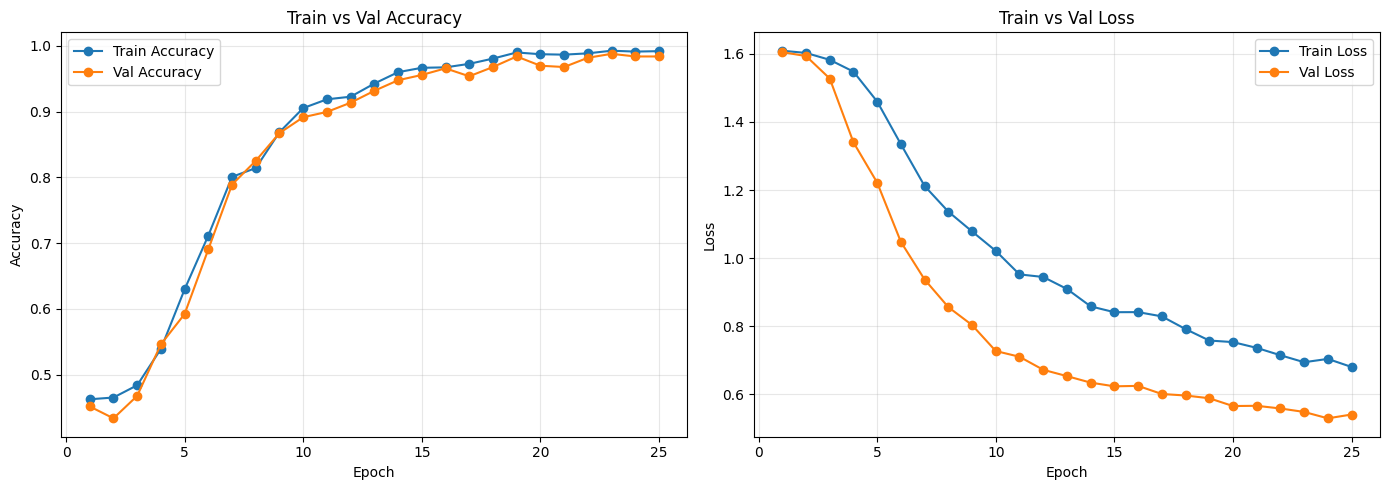

In [89]:
# ================================================================
# Train vs Val Accuracy & Loss curves (Scratch BiGRU-RAG model)
# ================================================================
import matplotlib.pyplot as plt

epochs_range = range(1, len(history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, history["train_acc"], marker='o', label='Train Accuracy')
axes[0].plot(epochs_range, history["val_acc"], marker='o', label='Val Accuracy')
axes[0].set_title('Train vs Val Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, history["train_loss"], marker='o', label='Train Loss')
axes[1].plot(epochs_range, history["val_loss"], marker='o', label='Val Loss')
axes[1].set_title('Train vs Val Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('scratch_rag_train_val_curves.png', dpi=150)
plt.show()

### Hyperparameter Tuning
Search over `hidden_dim`, `num_layers`, `dropout`, `lr`, `weight_decay` using short trial runs, then verify the top candidates across multiple seeds before trusting the ranking.

In [90]:
def train_one_config(cfg, epochs=10, patience=3, verbose=False, track_history=False):
    torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
    random.seed(SEED); np.random.seed(SEED)
    model = OptionScorer(
        vocab_size=len(vocab), embed_dim=cfg["embed_dim"],
        hidden_dim=cfg["hidden_dim"], num_layers=cfg["num_layers"],
        dropout=cfg["dropout"]
    ).to(device)
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=cfg["lr"],
        weight_decay=cfg["weight_decay"]
    )
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode='min',
        factor=0.5,
        patience=2
    )
    best_val_loss, bad_epochs = float('inf'), 0
    best_map3 = 0.0      # for logging/reference only
    best_state = None
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_map3": [],
        "val_map3": []
    } if track_history else None
    for epoch in range(1, epochs + 1):
        model.train()
        total_train_loss = 0.0
        for ids, mask, labels in train_loader:
            ids, mask = ids.to(device), mask.to(device)
            labels_t = torch.tensor(labels).to(device)
            optimizer.zero_grad()
            scores = model(ids, mask)
            loss = criterion(scores, labels_t)
            loss.backward()
            optimizer.step()
            if track_history:
                total_train_loss += loss.item()
        model.eval()
        all_top3, total_loss = [], 0.0
        with torch.no_grad():
            for ids, mask, labels in val_loader:
                ids, mask = ids.to(device), mask.to(device)
                labels_t = torch.tensor(labels).to(device)
                scores = model(ids, mask)
                total_loss += criterion(scores, labels_t).item()
                top3 = torch.topk(scores, k=3, dim=1).indices.cpu().tolist()
                all_top3.extend(top3)
        val_loss = total_loss / len(val_loader)
        preds = [[OPTIONS[i] for i in row] for row in all_top3]
        actuals = val_split['answer'].tolist()
        map3 = sum(apk(a, p) for a, p in zip(actuals, preds)) / len(actuals)
        scheduler.step(val_loss)
        if track_history:
            train_loss_avg = total_train_loss / len(train_loader)
            all_top3_tr = []
            with torch.no_grad():
                for ids, mask, labels in train_eval_loader:
                    ids, mask = ids.to(device), mask.to(device)
                    scores = model(ids, mask)
                    top3 = torch.topk(scores, k=3, dim=1).indices.cpu().tolist()
                    all_top3_tr.extend(top3)
            preds_tr = [[OPTIONS[i] for i in row] for row in all_top3_tr]
            actuals_tr = train_split['answer'].tolist()
            train_map3 = sum(apk(a, p) for a, p in zip(actuals_tr, preds_tr)) / len(actuals_tr)
            history["train_loss"].append(train_loss_avg)
            history["val_loss"].append(val_loss)
            history["train_map3"].append(train_map3)
            history["val_map3"].append(map3)
        if verbose:
            print(f"  epoch {epoch}: val_loss={val_loss:.4f} val_map3={map3:.4f}")
        if val_loss < best_val_loss:                 # CHANGED: lower loss wins, not higher map3
            best_val_loss, bad_epochs = val_loss, 0
            best_map3 = map3
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break
    if track_history:
        return best_val_loss, best_map3, best_state, history
    return best_val_loss, best_map3, best_state

In [91]:
import itertools, copy

search_space = {
    "embed_dim":    [100],
    "hidden_dim":   [64, 96],
    "num_layers":   [1, 2],
    "dropout":      [0.4, 0.45, 0.5],
    "lr":           [1e-3, 5e-4],
    "weight_decay": [3e-4, 1e-3],
}

keys = list(search_space.keys())
all_combos = list(itertools.product(*search_space.values()))
random.seed(SEED)
random.shuffle(all_combos)
trial_combos = all_combos[:20]   # sample 20 configs instead of full grid (72 combos)

results = []
for combo in trial_combos:
    cfg = dict(zip(keys, combo))
    print(f"Trying: {cfg}")
    val_loss, map3, state = train_one_config(cfg, epochs=10, patience=3)
    print(f"  -> val_loss = {val_loss:.4f}  (val_map3 = {map3:.4f})\n")
    results.append({"cfg": cfg, "val_loss": val_loss, "map3": map3, "state": state})

best_result = min(results, key=lambda r: r["val_loss"])
print("BEST CONFIG:", best_result["cfg"])
print("BEST VAL LOSS:", best_result["val_loss"], "| val_map3:", best_result["map3"])

Trying: {'embed_dim': 100, 'hidden_dim': 96, 'num_layers': 1, 'dropout': 0.45, 'lr': 0.001, 'weight_decay': 0.001}
  -> val_loss = 0.9513  (val_map3 = 0.8564)

Trying: {'embed_dim': 100, 'hidden_dim': 64, 'num_layers': 2, 'dropout': 0.5, 'lr': 0.0005, 'weight_decay': 0.001}
  -> val_loss = 1.4010  (val_map3 = 0.6854)

Trying: {'embed_dim': 100, 'hidden_dim': 96, 'num_layers': 1, 'dropout': 0.4, 'lr': 0.001, 'weight_decay': 0.0003}
  -> val_loss = 0.7718  (val_map3 = 0.9280)

Trying: {'embed_dim': 100, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.0005, 'weight_decay': 0.0003}
  -> val_loss = 1.2914  (val_map3 = 0.7313)

Trying: {'embed_dim': 100, 'hidden_dim': 64, 'num_layers': 2, 'dropout': 0.5, 'lr': 0.001, 'weight_decay': 0.001}
  -> val_loss = 1.1463  (val_map3 = 0.7701)

Trying: {'embed_dim': 100, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.5, 'lr': 0.001, 'weight_decay': 0.001}
  -> val_loss = 1.0972  (val_map3 = 0.8454)

Trying: {'embed_dim': 100, 'hidden_dim': 

In [92]:
# lowest val_loss first, not highest map3
top_candidates = sorted(results, key=lambda r: r["val_loss"])[:4]

seed_check = []
for cand in top_candidates:
    cfg = cand["cfg"]
    losses, map3s = [], []
    for seed in [42, 123, 777]:
        SEED = seed
        val_loss, map3, _ = train_one_config(cfg, epochs=10, patience=3)
        losses.append(val_loss)
        map3s.append(map3)
    seed_check.append({
        "cfg": cfg,
        "mean_loss": np.mean(losses),
        "std_loss": np.std(losses),
        "mean_map3": np.mean(map3s),
        "losses": losses,
    })

for s in seed_check:
    print(f"{s['cfg']} -> mean_val_loss={s['mean_loss']:.4f} std={s['std_loss']:.4f} "
          f"(mean_map3={s['mean_map3']:.4f})")

{'embed_dim': 100, 'hidden_dim': 64, 'num_layers': 2, 'dropout': 0.4, 'lr': 0.001, 'weight_decay': 0.0003} -> mean_val_loss=0.7733 std=0.0270 (mean_map3=0.9285)
{'embed_dim': 100, 'hidden_dim': 96, 'num_layers': 1, 'dropout': 0.4, 'lr': 0.001, 'weight_decay': 0.0003} -> mean_val_loss=0.7501 std=0.0154 (mean_map3=0.9347)
{'embed_dim': 100, 'hidden_dim': 64, 'num_layers': 1, 'dropout': 0.45, 'lr': 0.001, 'weight_decay': 0.0003} -> mean_val_loss=0.8311 std=0.0361 (mean_map3=0.8981)
{'embed_dim': 100, 'hidden_dim': 96, 'num_layers': 1, 'dropout': 0.45, 'lr': 0.001, 'weight_decay': 0.0003} -> mean_val_loss=0.8609 std=0.0570 (mean_map3=0.8964)


In [93]:
# ---------------------------------------------------------------------------
# Pick the config with the LOWEST multi-seed mean val LOSS (not just single-run peak),
# then retrain it fully for the final checkpoint.
# --------------------------------------------------------------------------------------
best_entry = min(seed_check, key=lambda s: s["mean_loss"])   # FIXED: min + correct key
best_cfg = best_entry["cfg"]
print("Selected best config (by multi-seed mean val_loss):", best_cfg)
print(f"Multi-seed mean val_loss: {best_entry['mean_loss']:.4f} (std={best_entry['std_loss']:.4f})")
print(f"Multi-seed mean val_map3 (reference only): {best_entry['mean_map3']:.4f}")

SEED = 42
torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
random.seed(SEED); np.random.seed(SEED)

final_val_loss, final_map3, final_state, tuned_history = train_one_config(
    best_cfg,
    epochs=25,
    patience=5,
    verbose=True,
    track_history=True
)

tuned_model = OptionScorer(
    vocab_size=len(vocab), embed_dim=best_cfg["embed_dim"],
    hidden_dim=best_cfg["hidden_dim"], num_layers=best_cfg["num_layers"],
    dropout=best_cfg["dropout"]
).to(device)
tuned_model.load_state_dict(final_state)
torch.save(tuned_model.state_dict(), "best_scratch_rag_model_tuned.pt")

print(f"\nSaved tuned model -> best_scratch_rag_model_tuned.pt")
print(f"Final val_loss = {final_val_loss:.4f}  |  Final val_map3 = {final_map3:.4f}")

Selected best config (by multi-seed mean val_loss): {'embed_dim': 100, 'hidden_dim': 96, 'num_layers': 1, 'dropout': 0.4, 'lr': 0.001, 'weight_decay': 0.0003}
Multi-seed mean val_loss: 0.7501 (std=0.0154)
Multi-seed mean val_map3 (reference only): 0.9347
  epoch 1: val_loss=1.6040 val_map3=0.5472
  epoch 2: val_loss=1.5855 val_map3=0.5833
  epoch 3: val_loss=1.3719 val_map3=0.6499
  epoch 4: val_loss=1.2149 val_map3=0.7272
  epoch 5: val_loss=1.4025 val_map3=0.7246
  epoch 6: val_loss=1.0291 val_map3=0.8009
  epoch 7: val_loss=0.9528 val_map3=0.8417
  epoch 8: val_loss=0.8926 val_map3=0.8611
  epoch 9: val_loss=0.8237 val_map3=0.8996
  epoch 10: val_loss=0.7837 val_map3=0.9257
  epoch 11: val_loss=0.7323 val_map3=0.9297
  epoch 12: val_loss=0.6939 val_map3=0.9508
  epoch 13: val_loss=0.6666 val_map3=0.9578
  epoch 14: val_loss=0.6406 val_map3=0.9762
  epoch 15: val_loss=0.6345 val_map3=0.9729
  epoch 16: val_loss=0.6115 val_map3=0.9729
  epoch 17: val_loss=0.6089 val_map3=0.9756
  epoc

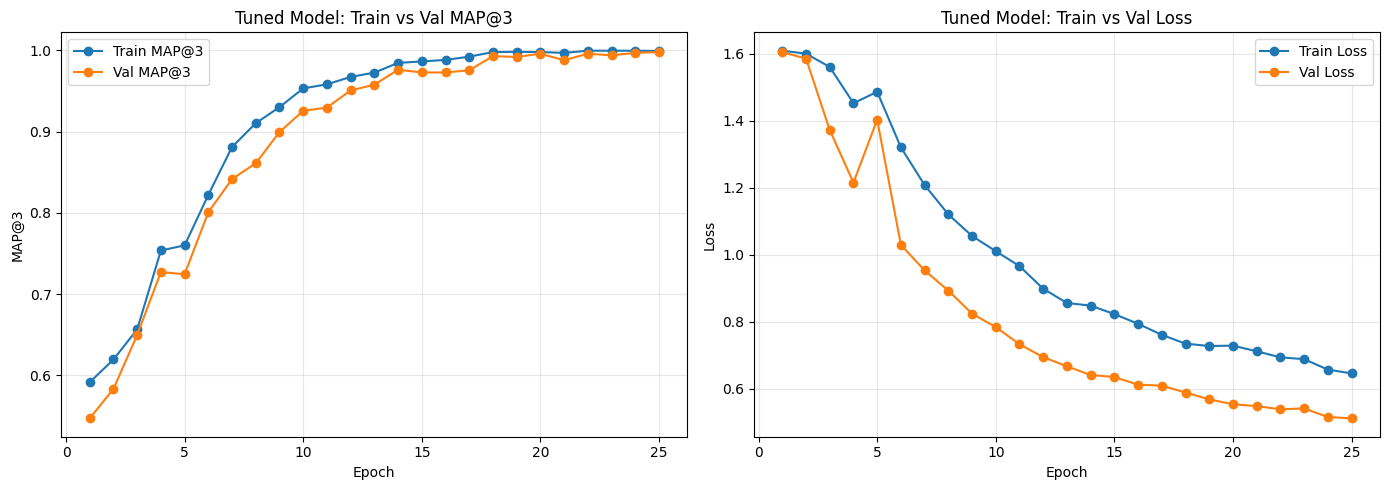

Final train MAP@3: 0.9993
Final val MAP@3:   0.9980
Train-Val gap:     0.0013
-> Train and val are close and reasonably high: healthy fit.


In [94]:
# ================================================================
# Train vs Val Accuracy & Loss curves (Tuned BiGRU-RAG model)
# Same diagnostic as the baseline plot -- compare train vs val gap
# to check overfitting / underfitting / healthy fit.
# ================================================================
import matplotlib.pyplot as plt

epochs_range = range(1, len(tuned_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(epochs_range, tuned_history["train_map3"], marker='o', label='Train MAP@3')
axes[0].plot(epochs_range, tuned_history["val_map3"], marker='o', label='Val MAP@3')
axes[0].set_title('Tuned Model: Train vs Val MAP@3')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('MAP@3')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, tuned_history["train_loss"], marker='o', label='Train Loss')
axes[1].plot(epochs_range, tuned_history["val_loss"], marker='o', label='Val Loss')
axes[1].set_title('Tuned Model: Train vs Val Loss')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('tuned_model_train_val_curves.png', dpi=150)
plt.show()

# Quick read: gap between final train_map3 and val_map3 tells you the fit type
final_gap = tuned_history["train_map3"][-1] - tuned_history["val_map3"][-1]
print(f"Final train MAP@3: {tuned_history['train_map3'][-1]:.4f}")
print(f"Final val MAP@3:   {tuned_history['val_map3'][-1]:.4f}")
print(f"Train-Val gap:     {final_gap:.4f}")
if final_gap > 0.05:
    print("-> Train notably higher than val: overfitting signal.")
elif tuned_history['val_map3'][-1] < 0.6:
    print("-> Both train and val are low: underfitting signal.")
else:
    print("-> Train and val are close and reasonably high: healthy fit.")

In [95]:
# ================================================================
# Compare Baseline vs Tuned model on val set -> pick the better one for prediction
# ==================================================================================

def evaluate_model(eval_model, loader, df):
    eval_model.eval()
    all_top3 = []
    total_loss = 0.0
    criterion_eval = nn.CrossEntropyLoss(label_smoothing=0.1)
    with torch.no_grad():
        for ids, mask, labels in loader:
            ids, mask = ids.to(device), mask.to(device)
            labels_t = torch.tensor(labels).to(device)
            scores = eval_model(ids, mask)
            total_loss += criterion_eval(scores, labels_t).item()
            top3 = torch.topk(scores, k=3, dim=1).indices.cpu().tolist()
            all_top3.extend(top3)
    avg_loss = total_loss / len(loader)
    preds = [[OPTIONS[i] for i in row] for row in all_top3]
    actuals = df['answer'].tolist()
    map3 = sum(apk(a, p) for a, p in zip(actuals, preds)) / len(actuals)
    return avg_loss, map3

# --- Load baseline (default hidden_dim=64, num_layers=1, dropout=0.4) ---
baseline_model = OptionScorer(vocab_size=len(vocab)).to(device)
baseline_model.load_state_dict(torch.load("best_scratch_rag_model.pt", map_location=device))

# --- Load tuned (best_cfg from HPO) ---
tuned_eval_model = OptionScorer(
    vocab_size=len(vocab), embed_dim=best_cfg["embed_dim"],
    hidden_dim=best_cfg["hidden_dim"], num_layers=best_cfg["num_layers"],
    dropout=best_cfg["dropout"]
).to(device)
tuned_eval_model.load_state_dict(torch.load("best_scratch_rag_model_tuned.pt", map_location=device))

baseline_loss, baseline_map3 = evaluate_model(baseline_model, val_loader, val_split)
tuned_loss, tuned_map3 = evaluate_model(tuned_eval_model, val_loader, val_split)

print("=" * 55)
print("Model Comparison (val set)")
print("=" * 55)
print(f"{'Model':<12} {'val_loss':>10} {'val_map3':>10}")
print(f"{'Baseline':<12} {baseline_loss:>10.4f} {baseline_map3:>10.4f}")
print(f"{'Tuned':<12} {tuned_loss:>10.4f} {tuned_map3:>10.4f}")
print("=" * 55)

# --- Pick the winner by val_loss (lower = better, less overfit / better calibrated) ---
if tuned_loss < baseline_loss:
    print(f"-> TUNED model wins (val_loss {tuned_loss:.4f} < {baseline_loss:.4f}). Using tuned for prediction.")
    winner_name = "tuned"
    pred_model = tuned_eval_model
    winner_cfg = best_cfg
else:
    print(f"-> BASELINE model wins (val_loss {baseline_loss:.4f} <= {tuned_loss:.4f}). Using baseline for prediction.")
    winner_name = "baseline"
    pred_model = baseline_model
    winner_cfg = {"embed_dim": 100, "hidden_dim": 64, "num_layers": 1, "dropout": 0.4}

pred_model.eval()

Model Comparison (val set)
Model          val_loss   val_map3
Baseline         0.5288     0.9920
Tuned            0.5112     0.9980
-> TUNED model wins (val_loss 0.5112 < 0.5288). Using tuned for prediction.


OptionScorer(
  (embedding): Embedding(5461, 100, padding_idx=0)
  (embed_drop): Dropout(p=0.4, inplace=False)
  (gru): GRU(100, 96, batch_first=True, bidirectional=True)
  (attn): Linear(in_features=192, out_features=1, bias=True)
  (fc): Sequential(
    (0): Linear(in_features=192, out_features=96, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.4, inplace=False)
    (3): Linear(in_features=96, out_features=1, bias=True)
  )
)

In [96]:
# ---------------------------------------------------------------------------
# Final prediction — uses whichever model (baseline or tuned) won the comparison above
# ---------------------------------------------------------------------------
print(f"Generating predictions using the {winner_name.upper()} model (config: {winner_cfg})")

def predict_top3(loader):
    pred_model.eval()
    all_top3 = []
    with torch.no_grad():
        for ids, mask, _ in loader:
            ids, mask = ids.to(device), mask.to(device)
            scores = pred_model(ids, mask)
            top3 = torch.topk(scores, k=3, dim=1).indices.cpu().tolist()
            all_top3.extend(top3)
    return [[OPTIONS[i] for i in row] for row in all_top3]

test_loader = DataLoader(
    MCQDataset(test_dataset, vocab, augment=False),
    batch_size=64,
    shuffle=False
)
test_preds = predict_top3(test_loader)

test_df_out = test_dataset.copy()
test_df_out['rag_scratch_pred'] = [' '.join(p) for p in test_preds]

submission = pd.DataFrame({
    'ID': test_df_out['id'],
    'Prediction': test_df_out['rag_scratch_pred'],
})
submission.to_csv('submission_scratch_rag.csv', index=False)
print(submission.head(10).to_string(index=False))

Generating predictions using the TUNED model (config: {'embed_dim': 100, 'hidden_dim': 96, 'num_layers': 1, 'dropout': 0.4, 'lr': 0.001, 'weight_decay': 0.0003})
 ID Prediction
  1      A B E
  2      B E C
  3      B E C
  4      E D C
  5      C A D
  6      D B A
  7      E D A
  8      B E A
  9      C D A
 10      B D E
